# ForwardGNN benchmark: WebKB (Cornell, Texas, Washington) and Reddit

Benchmarks the training approaches of *Forward Learning of Graph Neural Networks* (Park et al., ICLR 2024; code `facebookresearch/forwardgnn`) on GCN, GraphSAGE and GAT at depths 1 to 4.

| Method | forwardgnn model name | Script |
|---|---|---|
| Backpropagation (BP) | `GNN-<arch>` | `train_backprop.py` |
| Single-Forward (SF) | `GNN_SingleForward-<arch>` | `train_forward.py` |
| SF with top-down signal, Top2Input | `GNN_Top2Input_SingleForward-<arch>` | `train_forward.py --alternating-update` |
| SF with top-down signal, Top2Loss | `GNN_Top2Loss_SingleForward-<arch>` | `train_forward.py --alternating-update` |

**Grid:** 4 datasets × 3 architectures × 4 methods × 4 depths = 192 configurations, each trained on 5 data splits = 960 runs. Every depth is its own training run, for every method.

**Recorded for every run:** test accuracy, macro-F1 (plus micro-F1, weighted-F1 and per-class F1), training time, training time without test-set monitoring, peak GPU memory, epochs. Section 9 defines each one.

**Datasets.** All four go through one preprocessing pipeline, summarized in section 7 and documented in `Experiments/DATASET_PREPROCESSING.md`:

| Dataset | Version | Nodes | Undirected edges used | Features | Classes |
|---|---|---|---|---|---|
| WebKB-Cornell | LINQS WebKB release | 195 | 283 | 1,703 (binary) | 5 |
| WebKB-Texas | LINQS WebKB release | 187 | 280 | 1,703 (binary) | 5 |
| WebKB-Washington | LINQS WebKB release | 230 | 366 | 1,703 (binary) | 5 |
| Reddit2 | GraphSAINT version of Reddit (PyG `Reddit2`) | 232,965 | 11,606,919 | 602 | 41 |

**How to run**
1. Runtime → Change runtime type → **A100 GPU**. WebKB alone also runs on a T4 or L4.
2. Run sections 0 to 10 in order (about 10 minutes the first time, mostly building the environment).
3. Run section 11 (WebKB), then the cells of section 12 (Reddit2, one architecture per cell). Each run is written to Drive the moment it finishes, and finished runs are skipped. After a disconnect, re-run sections 0 to 6 and 9, then the cell you were on.
4. Sections 13 to 16 build tables and figures from whatever has finished so far. They need only sections 0 and 2.

As in `forwardgnn_pubmed_colab.ipynb`, the notebook kernel only launches jobs. Training runs in a separate Python 3.10 environment with `torch 1.13.1` and `torch_geometric 2.2.0`, which forwardgnn requires.

## 0. Settings

Edit only this cell. The hyper-parameters are those of forwardgnn's `exp/nodeclass/*.sh` scripts, the same for every method. `EXP_SETTING` names the folders that hold the results; it includes both switches below, so results from different settings never mix.

In [ ]:
PROJECT_DIR = '/content/drive/MyDrive/forwardgnn-experiments'   # same Drive folder as the earlier notebooks

DATASETS = ['WebKB-Cornell', 'WebKB-Texas', 'WebKB-Washington', 'Reddit2']
ARCHS    = ['GCN', 'SAGE', 'GAT']
METHODS  = ['BP', 'SF', 'SF-Top2Input', 'SF-Top2Loss']
DEPTHS   = [1, 2, 3, 4]
NUM_RUNS = 5        # run i uses data split i and seed 10100 + 3i (forwardgnn's SeedManager)

HPARAMS = {'epochs': 1000, 'val_every': 2, 'lr': 0.001, 'patience': 100, 'num_hidden': 128, 'seed': 100}

# Message passing. 'sparse' = SparseTensor adjacency: the same function, without per-edge feature tensors
# (section 8 checks this on your GPU); needed for Reddit2. 'edge_index' = forwardgnn's original path.
MP_BACKEND = 'sparse'
# Feature normalization. 'standardize' = column-wise z-score over all nodes (see DATASET_PREPROCESSING.md);
# 'row_l1' = forwardgnn's NormalizeFeatures(), the transform its CitationFull/Amazon/GitHub runs use.
FEATURE_NORM = 'standardize'

EXP_SETTING = f'webkb-reddit-{MP_BACKEND}-{FEATURE_NORM}'
RETRY_FAILED = False   # True: try again configurations whose last attempt ran out of memory or failed

FORWARDGNN_COMMIT = '73fe25720afd0f854e49c099f9c2517c0549617d'   # the repository's only commit, pinned

## 1. Check the runtime

In [ ]:
import shutil, subprocess

smi = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                     capture_output=True, text=True) if shutil.which('nvidia-smi') else None
if smi is None or smi.returncode != 0:
    print('No GPU. Switch the runtime to a GPU: time and memory numbers are only meaningful on one.')
else:
    print(smi.stdout.strip())
    gpu_gb = int(smi.stdout.strip().splitlines()[0].split(',')[-1].split()[0]) / 1024
    if gpu_gb < 70:
        print(f'{gpu_gb:.0f} GB GPU: enough for WebKB. On Reddit2 some GAT (and possibly deep backprop) '
              'configurations will run out of memory; they are recorded and reported as OOM.')

NVIDIA A100-SXM4-80GB, 81920 MiB


## 2. Mount Drive

Data, splits and results live on Drive, so a disconnect costs nothing. `bench_records/<EXP_SETTING>/` holds one JSON per run (the benchmark's results), `logs/` the full output of every job, and `reports/` the tables and figures.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path

for sub in ['data', 'datasplits', 'results', 'bench_records', 'logs', 'reports']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)
RECORDS_DIR = Path(PROJECT_DIR) / 'bench_records' / EXP_SETTING
LOG_DIR     = Path(PROJECT_DIR) / 'logs' / EXP_SETTING
REPORT_DIR  = Path(PROJECT_DIR) / 'reports' / EXP_SETTING
for d in (RECORDS_DIR, LOG_DIR, REPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('records:', RECORDS_DIR)

Mounted at /content/drive
records: /content/drive/MyDrive/forwardgnn-experiments/bench_records/webkb-reddit-sparse-standardize


## 3. Clone forwardgnn and point its folders at Drive

`src/settings.py` hardcodes `data/`, `datasplits/` and `results/` relative to the repository, so those three are symlinked into Drive instead of patching the code. The repository itself is never modified: the benchmark code goes into a separate `src/fgnn_bench/` package (section 6).

In [ ]:
import os, shutil, subprocess

REPO = '/content/forwardgnn'
SRC = f'{REPO}/src'
if not os.path.exists(REPO):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/facebookresearch/forwardgnn.git', REPO], check=True)
    subprocess.run(['git', '-C', REPO, 'checkout', '-q', FORWARDGNN_COMMIT], check=True)
for sub in ['data', 'datasplits', 'results']:
    p = f'{REPO}/{sub}'
    if os.path.islink(p):
        os.unlink(p)
    elif os.path.isdir(p):
        shutil.rmtree(p)
    os.symlink(f'{PROJECT_DIR}/{sub}', p)
print(subprocess.run(['git', '-C', REPO, 'log', '-1', '--format=%H %s'], capture_output=True, text=True).stdout)

73fe25720afd0f854e49c099f9c2517c0549617d Initial commit



## 4. Build the Python 3.10 training environment (about 5 minutes, once per session)

Same environment as `forwardgnn_pubmed_colab.ipynb`. forwardgnn needs `torch==1.13.1` and `torch_geometric==2.2.0`, because `src/gnn/message_passing.py` vendors PyG 2.2 internals that were removed in PyG 2.3. Colab's Python is too new for torch 1.13, so `uv` fetches a standalone Python 3.10.

In [ ]:
import os, re, shutil, subprocess, urllib.request
from urllib.parse import urljoin

VENV    = '/content/fgnn-env'
VENV_PY = f'{VENV}/bin/python'
HAS_GPU = shutil.which('nvidia-smi') is not None and subprocess.run(['nvidia-smi'], capture_output=True).returncode == 0

TORCH_BUILD = 'cu117' if HAS_GPU else 'cpu'
TORCH_INDEX = f'https://download.pytorch.org/whl/{TORCH_BUILD}'
PYG_WHEELS  = f'https://data.pyg.org/whl/torch-1.13.1+{TORCH_BUILD}.html'
print('Building for:', TORCH_BUILD)

def sh(cmd):
    print('$', ' '.join(cmd))
    r = subprocess.run(cmd, text=True, capture_output=True)
    print(r.stdout[-1500:])
    if r.returncode != 0:
        print('----- STDERR -----')
        print(r.stderr[-4000:])
        raise RuntimeError(f'Failed: {" ".join(cmd)}')

if not os.path.exists(VENV_PY):
    sh(['uv', 'venv', '--seed', '--python', '3.10', VENV])
sh([VENV_PY, '-m', 'ensurepip', '--upgrade'])
sh([VENV_PY, '-m', 'pip', 'install', '-q', '--upgrade', 'pip', 'setuptools', 'wheel'])
PIP = [VENV_PY, '-m', 'pip', 'install', '-q']

sh(PIP + ['numpy==1.24.4', 'scipy==1.10.1'])   # numpy<2 first: torch 1.13 is built against the 1.x ABI
sh(PIP + [f'torch==1.13.1+{TORCH_BUILD}', '--index-url', TORCH_INDEX])

# torch_scatter / torch_sparse: pick the prebuilt wheels explicitly so pip never compiles from source
tag = subprocess.run([VENV_PY, '-c', 'import sys;print(f"cp{sys.version_info.major}{sys.version_info.minor}")'],
                     capture_output=True, text=True).stdout.strip()
html = urllib.request.urlopen(PYG_WHEELS).read().decode()
wheels = []
for pkg in ['torch_scatter', 'torch_sparse']:
    hits = re.findall(rf'href="([^"]*{pkg}-[^"]*{tag}-{tag}-linux_x86_64\.whl[^"]*)"', html)
    if not hits:
        raise RuntimeError(f'No {pkg} wheel for {tag} at {PYG_WHEELS}')
    wheels.append(urljoin(PYG_WHEELS, hits[-1]))
    print(f'  {pkg}: {wheels[-1].split("/")[-1][:70]}')
sh(PIP + wheels)
sh(PIP + ['torch-geometric==2.2.0', 'scikit-learn==1.3.2', 'tqdm'])
print('\nEnvironment built.')

Building for: cu117
$ uv venv --seed --python 3.10 /content/fgnn-env

$ /content/fgnn-env/bin/python -m ensurepip --upgrade
Looking in links: /tmp/tmpd5tq06kj

$ /content/fgnn-env/bin/python -m pip install -q --upgrade pip setuptools wheel

$ /content/fgnn-env/bin/python -m pip install -q numpy==1.24.4 scipy==1.10.1

$ /content/fgnn-env/bin/python -m pip install -q torch==1.13.1+cu117 --index-url https://download.pytorch.org/whl/cu117

  torch_scatter: torch_scatter-2.1.1%2Bpt113cu117-cp310-cp310-linux_x86_64.whl
  torch_sparse: torch_sparse-0.6.17%2Bpt113cu117-cp310-cp310-linux_x86_64.whl
$ /content/fgnn-env/bin/python -m pip install -q https://data.pyg.org/whl/torch-1.13.0%2Bcu117/torch_scatter-2.1.1%2Bpt113cu117-cp310-cp310-linux_x86_64.whl https://data.pyg.org/whl/torch-1.13.0%2Bcu117/torch_sparse-0.6.17%2Bpt113cu117-cp310-cp310-linux_x86_64.whl

$ /content/fgnn-env/bin/python -m pip install -q torch-geometric==2.2.0 scikit-learn==1.3.2 tqdm


Environment built.


## 5. Verify the environment

Imports forwardgnn's vendored PyG 2.2 internals (this is where a wrong PyG version fails) and runs the compiled `torch_scatter` / `torch_sparse` CUDA kernels once, so an unsupported GPU fails here rather than mid-sweep.

In [ ]:
check = r"""
import sys, torch, torch_geometric, numpy, sklearn
print('python', sys.version.split()[0], '| torch', torch.__version__, '| torch_geometric', torch_geometric.__version__,
      '| numpy', numpy.__version__, '| scikit-learn', sklearn.__version__)
print('cuda available:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
sys.path.insert(0, '/content/forwardgnn/src')
from gnn import GNNConv                                  # vendored PyG 2.2 internals
import torch_scatter
from torch_sparse import SparseTensor
if torch.cuda.is_available():
    x = torch.randn(5, 3, device='cuda')
    idx = torch.tensor([0, 0, 1, 2, 2], device='cuda')
    print('torch_scatter kernel OK:', tuple(torch_scatter.scatter(x, idx, dim=0, reduce='mean').shape))
    adj = SparseTensor(row=idx, col=torch.arange(5, device='cuda'), sparse_sizes=(3, 5))
    print('torch_sparse kernel OK:', tuple((adj @ x).shape))
print('environment OK')
"""
open('/content/_check.py', 'w').write(check)
!{VENV_PY} /content/_check.py

python 3.10.21 | torch 1.13.1+cu117 | torch_geometric 2.2.0 | numpy 1.24.4 | scikit-learn 1.3.2
cuda available: True NVIDIA A100-SXM4-80GB
torch_scatter kernel OK: (3, 3)
torch_sparse kernel OK: (3, 3)
environment OK


## 6. Install the benchmark helpers (`src/fgnn_bench/`)

Five files, written next to forwardgnn's code. forwardgnn itself stays untouched; these modules hook into it at runtime.

| File | What it does |
|---|---|
| `datasets_ext.py` | Downloads the raw WebKB and Reddit2 files, checks their SHA-256, applies the shared preprocessing (section 7) and registers the four datasets with forwardgnn's `load_dataset`, so `DataSplit` and both training scripts use them like built-in datasets. |
| `sparse_backend.py` | Optional SparseTensor message passing (section 8). |
| `run_bench.py` | Runs `train_backprop.py` / `train_forward.py` unmodified, in-process, and writes one record per run with the metrics of section 9. |
| `check_backend.py` | Compares the sparse backend with forwardgnn's `edge_index` path on your GPU. |

`run_bench.py` avoids two pitfalls of the earlier notebooks:
1. `run_with_mem.py` (in `forwardgnn_gat_sage_memory.ipynb`) reset the peak-memory counter on *every* `save_run_result` call. Single-forward also calls that function after each layer while training, so the peak it reported for a single-forward run covered only the final evaluation pass. `run_bench.py` resets the counters once, at the start of each run.
2. forwardgnn decides whether a run is finished from its own result files. A depth-4 single-forward job also writes, and overwrites, those files for depths 1 to 3, so they end up describing intermediate states of the deepest job, and a shallower job started afterwards is skipped. `run_bench.py` keeps its own per-run records, so every depth is trained independently.

In [ ]:
import os
os.makedirs('/content/forwardgnn/src/fgnn_bench', exist_ok=True)

In [ ]:
%%writefile /content/forwardgnn/src/fgnn_bench/__init__.py
"""Benchmark helpers for running facebookresearch/forwardgnn on WebKB (LINQS) and Reddit2.

Modules (all run inside the Python 3.10 / torch 1.13.1 / PyG 2.2.0 training environment):
    datasets_ext    download, clean and register the datasets with forwardgnn's loader
    sparse_backend  optional SparseTensor message passing (same math, no per-edge feature tensors)
    run_bench       launcher that runs train_backprop.py / train_forward.py and records metrics per run
"""

Writing /content/forwardgnn/src/fgnn_bench/__init__.py


In [ ]:
%%writefile /content/forwardgnn/src/fgnn_bench/datasets_ext.py
"""Prepare LINQS WebKB (Cornell, Texas, Washington) and GraphSAINT Reddit2 for forwardgnn.

Every dataset goes through the same pipeline (DATASET_PREPROCESSING.md explains each choice):

  1. download the released raw files and check their size and SHA-256
  2. parse node ids, features, labels and directed links exactly as released
  3. drop links whose endpoints are not in the node list, drop duplicate links, remove self-loops
  4. make the graph undirected: add every reverse edge, then deduplicate again
  5. keep every node (isolated ones included) and every class; labels become 0..K-1
  6. store the features as float32 without rescaling
  7. when loaded for training: standardise every feature column over all nodes (z-score; no labels
     are used, so this is legitimate in the transductive setting); constant columns become 0

`install()` makes forwardgnn's `load_dataset` return these graphs, and forwardgnn's `DataSplit` builds
the same five random 64/16/20 train/val/test splits it uses for every dataset. Step 7 can be switched
to forwardgnn's own `NormalizeFeatures()` (FGNN_FEATURE_NORM=row_l1) for comparability with runs on
its built-in datasets; DATASET_PREPROCESSING.md explains why that is not the default.

CLI, run from forwardgnn/src inside the training environment:
    python -m fgnn_bench.datasets_ext WebKB-Cornell WebKB-Texas WebKB-Washington Reddit2 \
        --raw-dir /content/fgnn_raw --splits --report /path/to/dataset_report.md
"""
import argparse
import hashlib
import json
import os
import shutil
import sys
import tarfile
import time
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import torch_geometric
from torch_geometric.data import Data, InMemoryDataset
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.utils import coalesce, is_undirected, to_undirected

import settings

WEBKB_URL = 'https://linqs-data.soe.ucsc.edu/public/lbc/WebKB.tgz'
WEBKB_SIZE = 132209
WEBKB_SHA256 = '62630a2427e5aeffc1158ad4e6ee275a0dacdcff9ef8b4506aef9c4805e75ab4'
WEBKB_CLASSES = ['course', 'faculty', 'project', 'staff', 'student']  # label id = list index

# GraphSAINT's release of Reddit, the same Google Drive files torch_geometric.datasets.Reddit2 uses.
# PyG 2.2.0 downloads them from docs.google.com/uc, which now answers the two large files with an HTML
# virus-scan page; drive.usercontent.google.com serves the bytes directly.
GDRIVE_URL = 'https://drive.usercontent.google.com/download?id={}&confirm=t'
REDDIT2_FILES = {  # name: (Drive id, size in bytes, SHA-256)
    'adj_full.npz': ('1sncK996BM5lpuDf75lDFqCiDZyErc1c2', 64866285,
                     '2e190c5216ead7018989fd26502c1455782abb39d3b316b714b0cbc8ced2a2dd'),
    'feats.npy': ('1ZsHaJ0ussP1W722krmEIp_8pwKAoi5b3', 1121959520,
                  '5a8a381f5bf80b06d5555cbf0aa5521958fed191c00400e02f4a9ea7d4bb2f41'),
    'class_map.json': ('1JF3Pjv9OboMNYs2aXRQGbJbc4t_nDd5u', 3089824,
                       'b15bb00caee03ee3b83dd382ce3470f5c677f53e75c53af2b1231fe6376a8487'),
    'role.json': ('1nJIKd77lcAGU4j-kVNx_AIGEkveIKz3A', 1752634,
                  '5efd0e9e75be6ddfc8411236e9b22d3b241c992d6311060f93f72091075ef518'),
}

# benchmark name -> WebKB university (None for Reddit2)
DATASETS = {
    'WebKB-Cornell': 'cornell',
    'WebKB-Texas': 'texas',
    'WebKB-Washington': 'washington',
    'Reddit2': None,
}

PIPELINE = [
    'download the released raw files; verify size and SHA-256',
    'parse nodes, features, labels and directed links as released',
    'drop links with unknown endpoints and duplicate links; remove self-loops',
    'symmetrise (add reverse edges) and deduplicate',
    'keep all nodes (incl. isolated) and all classes; labels mapped to 0..K-1',
    'features stored as float32, unscaled',
    'at load time: column-wise z-score over all nodes (FGNN_FEATURE_NORM, default standardize)',
    'splits: forwardgnn DataSplit, KFold(5, shuffle, random_state=101) -> 64/16/20 train/val/test',
]


class StandardizeFeatures:
    """Column-wise z-score over all nodes, (x - mean) / std with the population std; columns that are
    constant over the graph become 0. Uses no labels and no split information."""

    def __call__(self, data):
        mean = data.x.mean(dim=0, keepdim=True)
        std = data.x.std(dim=0, unbiased=False, keepdim=True)
        data.x = (data.x - mean) / torch.where(std > 0, std, torch.ones_like(std))
        return data

    def __repr__(self):
        return 'StandardizeFeatures()'


FEATURE_NORMS = {  # FGNN_FEATURE_NORM value -> transform applied every time the graph is loaded
    'standardize': StandardizeFeatures,
    'row_l1': NormalizeFeatures,  # forwardgnn's transform for CitationFull / Amazon / GitHub
    'none': None,
}


def feature_norm():
    name = os.environ.get('FGNN_FEATURE_NORM', 'standardize')
    if name not in FEATURE_NORMS:
        raise ValueError(f'FGNN_FEATURE_NORM={name!r}; choose from {sorted(FEATURE_NORMS)}')
    return name


def dataset_root(name):
    return Path(settings.DATA_ROOT) / 'fgnn_bench' / name


# ----------------------------------------------------------------------------------------- download

def _sha256(path, chunk=1 << 22):
    digest = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):
            digest.update(block)
    return digest.hexdigest()


def _fetch(url, dest, size, sha256, retries=3):
    """Download `url` to `dest` unless a verified copy is already there; return the path."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size == size and _sha256(dest) == sha256:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    part = dest.with_name(dest.name + '.part')
    for attempt in range(1, retries + 1):
        try:
            print(f'downloading {dest.name} ({size / 2 ** 20:.1f} MiB)', flush=True)
            request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(request, timeout=300) as response, open(part, 'wb') as f:
                shutil.copyfileobj(response, f, 1 << 22)
            got_size, got_sha = part.stat().st_size, _sha256(part)
            if got_size != size or got_sha != sha256:
                raise IOError(f'{dest.name}: expected {size} bytes with sha256 {sha256[:12]}..., '
                              f'got {got_size} bytes with sha256 {got_sha[:12]}...')
            os.replace(part, dest)
            return dest
        except Exception as exc:  # network hiccups, Drive quota pages, truncated files
            print(f'  attempt {attempt}/{retries} failed: {exc}', flush=True)
            if attempt == retries:
                raise
            time.sleep(10 * attempt)


# ------------------------------------------------------------------------------------------- parse

def _read_webkb(raw_dir, university):
    archive = _fetch(WEBKB_URL, Path(raw_dir) / 'WebKB.tgz', WEBKB_SIZE, WEBKB_SHA256)
    with tarfile.open(archive, 'r:gz') as tar:  # read members in memory; nothing is extracted
        content = tar.extractfile(f'webkb/{university}.content').read().decode('utf-8')
        cites = tar.extractfile(f'webkb/{university}.cites').read().decode('utf-8')

    # .content: "<page url> <1703 binary word indicators> <class>", tab separated
    node_ids, rows, labels = [], [], []
    for line in content.splitlines():
        if line.strip():
            fields = line.split('\t')
            node_ids.append(fields[0])
            rows.append(fields[1:-1])
            labels.append(fields[-1].strip())
    index = {node: i for i, node in enumerate(node_ids)}
    if len(index) != len(node_ids):
        raise ValueError(f'{university}: duplicate page ids')
    x = np.asarray(rows, dtype=np.float32)
    y = np.asarray([WEBKB_CLASSES.index(label) for label in labels], dtype=np.int64)

    # .cites: "<cited page> <citing page>"; the hyperlink points from the citing to the cited page
    src, dst, n_lines, n_dangling = [], [], 0, 0
    for line in cites.splitlines():
        if line.strip():
            cited, citing = line.split()
            n_lines += 1
            if cited in index and citing in index:
                src.append(index[citing])
                dst.append(index[cited])
            else:
                n_dangling += 1
    edge_index = torch.tensor([src, dst], dtype=torch.long)

    source = {
        'origin': 'WebKB, CMU World Wide Knowledge Base project (Craven et al., AAAI 1998)',
        'release': f'LINQS WebKB release, files webkb/{university}.content and webkb/{university}.cites',
        'files': {'WebKB.tgz': {'url': WEBKB_URL, 'bytes': WEBKB_SIZE, 'sha256': WEBKB_SHA256}},
    }
    raw = {'nodes': len(node_ids), 'links': n_lines, 'links_with_unknown_endpoint': n_dangling}
    return x, y, edge_index, list(WEBKB_CLASSES), source, raw


def _read_reddit2(raw_dir):
    paths = {name: _fetch(GDRIVE_URL.format(file_id), Path(raw_dir) / name, size, sha256)
             for name, (file_id, size, sha256) in REDDIT2_FILES.items()}

    adj = np.load(paths['adj_full.npz'])  # scipy CSR arrays: data, indices, indptr, shape
    n = int(adj['shape'][0])
    indptr, indices = adj['indptr'].astype(np.int64), adj['indices'].astype(np.int64)
    rows = np.repeat(np.arange(n, dtype=np.int64), np.diff(indptr))
    stored = adj['data'] != 0
    edge_index = torch.from_numpy(np.stack([rows[stored], indices[stored]]))

    x = np.load(paths['feats.npy']).astype(np.float32)  # released as float64
    with open(paths['class_map.json']) as f:
        class_map = json.load(f)
    y = np.full(n, -1, dtype=np.int64)
    for node, label in class_map.items():
        y[int(node)] = int(label)
    if (y < 0).any():
        raise ValueError('Reddit2: some nodes have no label')
    with open(paths['role.json']) as f:
        role = json.load(f)

    source = {
        'origin': 'Reddit posts, Sept. 2014 (Hamilton et al., GraphSAGE, NeurIPS 2017)',
        'release': 'GraphSAINT sparsified version (Zeng et al., ICLR 2020) = torch_geometric.datasets.Reddit2',
        'files': {name: {'url': GDRIVE_URL.format(file_id), 'bytes': size, 'sha256': sha256}
                  for name, (file_id, size, sha256) in REDDIT2_FILES.items()},
    }
    raw = {'nodes': n, 'links': int(stored.sum()), 'links_with_unknown_endpoint': 0,
           'official_split_not_used': {part: len(ids) for part, ids in role.items()}}
    label_names = [f'class_{k}' for k in range(int(y.max()) + 1)]
    return x, y, edge_index, label_names, source, raw


# ------------------------------------------------------------------------------------------- clean

def clean_edges(edge_index, num_nodes):
    """Steps 3-4 of the pipeline; returns the undirected edge_index and what was removed."""
    stats = {'links_parsed': int(edge_index.size(1))}
    edge_index = coalesce(edge_index, num_nodes=num_nodes)
    stats['duplicate_links'] = stats['links_parsed'] - int(edge_index.size(1))
    loops = edge_index[0] == edge_index[1]
    stats['self_loops'] = int(loops.sum())
    edge_index = edge_index[:, ~loops]
    directed = int(edge_index.size(1))
    edge_index = to_undirected(edge_index, num_nodes=num_nodes)
    undirected = int(edge_index.size(1)) // 2
    stats['reciprocal_link_pairs'] = directed - undirected
    stats['undirected_edges_incl_self_loops'] = undirected + stats['self_loops']
    stats['undirected_edges'] = undirected
    stats['edge_index_entries'] = int(edge_index.size(1))
    assert is_undirected(edge_index, num_nodes=num_nodes)
    assert not bool((edge_index[0] == edge_index[1]).any())
    return edge_index, stats


def _feature_stats(x):
    nonzero = x != 0
    row_sums = x.sum(1)
    stats = {
        'dim': int(x.shape[1]),
        'binary': bool(np.isin(x, (0.0, 1.0)).all()),
        'min': float(x.min()), 'max': float(x.max()), 'mean': float(x.mean()),
        'nonzero_fraction': float(nonzero.mean()),
        'all_zero_rows': int((~nonzero.any(1)).sum()),
        'constant_columns': int((x.max(0) == x.min(0)).sum()),
        'row_sum_min': float(row_sums.min()), 'row_sum_max': float(row_sums.max()),
    }
    if not stats['binary']:
        widest = np.argsort(-np.abs(x).max(0))[:5]
        stats['largest_magnitude_columns'] = [
            {'column': int(c), 'min': float(x[:, c].min()), 'max': float(x[:, c].max())} for c in widest]
    return stats


def _transformed_feature_stats(x):
    """What each FEATURE_NORMS option hands the model. `median_top_column_share` is the median over
    nodes of max_j |x_ij| / ||x_i||_2: how much a single column dominates a row's direction (the
    single-forward layers L2-normalise every row before using it)."""
    out = {}
    for name, transform in FEATURE_NORMS.items():
        if transform is None:
            continue
        z = transform()(Data(x=torch.from_numpy(x).clone())).x
        share = z.abs().max(dim=1).values / z.norm(dim=1).clamp(min=1e-12)
        out[name] = {'min': float(z.min()), 'max': float(z.max()), 'mean_abs': float(z.abs().mean()),
                     'median_top_column_share': float(share.median())}
    return out


def graph_stats(x, y, edge_index, label_names):
    n = x.shape[0]
    degree = torch.bincount(edge_index[0], minlength=n).numpy()
    same_label = (torch.from_numpy(y)[edge_index[0]] == torch.from_numpy(y)[edge_index[1]])
    return {
        'nodes': int(n),
        'undirected_edges': int(edge_index.size(1)) // 2,
        'edge_index_entries': int(edge_index.size(1)),
        'isolated_nodes': int((degree == 0).sum()),
        'degree_mean': float(degree.mean()), 'degree_median': float(np.median(degree)),
        'degree_max': int(degree.max()),
        'edge_homophily': float(same_label.float().mean()) if edge_index.size(1) else float('nan'),
        'num_classes': len(label_names),
        'label_names': label_names,
        'class_counts': np.bincount(y, minlength=len(label_names)).tolist(),
        'features': _feature_stats(x),
        'features_after_transform': _transformed_feature_stats(x),
    }


# ------------------------------------------------------------------------------------- prepare/load

def prepare(name, raw_root=None, force=False):
    """Run the pipeline for `name`; writes <root>/processed/data.pt and <root>/stats.json.

    Raw downloads go to <raw_root>/<name> (raw_root defaults to $FGNN_RAW_DIR, else <root>/raw is
    used directly). They are not needed again once the processed file exists."""
    if name not in DATASETS:
        raise ValueError(f'unknown dataset {name!r}; choose from {sorted(DATASETS)}')
    root = dataset_root(name)
    processed, stats_path = root / 'processed' / 'data.pt', root / 'stats.json'
    if processed.exists() and stats_path.exists() and not force:
        return json.loads(stats_path.read_text())

    raw_root = raw_root or os.environ.get('FGNN_RAW_DIR')
    raw_dir = Path(raw_root) / name if raw_root else root / 'raw'
    if DATASETS[name] is None:
        x, y, edge_index, label_names, source, raw = _read_reddit2(raw_dir)
    else:
        x, y, edge_index, label_names, source, raw = _read_webkb(raw_dir, DATASETS[name])
    if not (y.min() == 0 and len(np.unique(y)) == len(label_names)):
        raise ValueError(f'{name}: labels must cover 0..{len(label_names) - 1}')

    edge_index, cleaning = clean_edges(edge_index, num_nodes=x.shape[0])
    stats = {
        'dataset': name,
        'source': source,
        'raw': raw,
        'cleaning': cleaning,
        'processed': graph_stats(x, y, edge_index, label_names),
        'pipeline': PIPELINE,
        'versions': {'torch': torch.__version__, 'torch_geometric': torch_geometric.__version__,
                     'numpy': np.__version__, 'python': sys.version.split()[0]},
        'prepared_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    }

    data = Data(x=torch.from_numpy(x), edge_index=edge_index, y=torch.from_numpy(y))
    processed.parent.mkdir(parents=True, exist_ok=True)
    tmp = processed.with_name('data.pt.tmp')
    torch.save(InMemoryDataset.collate([data]), tmp)
    os.replace(tmp, processed)
    stats_path.write_text(json.dumps(stats, indent=2))
    return stats


class PreparedNodeDataset(InMemoryDataset):
    """The single graph written by prepare(). It defines no download()/process(), so PyG never
    looks for raw files once the processed file exists."""

    def __init__(self, root, transform=None):
        super().__init__(root, transform)
        self.data, self.slices = torch.load(self.processed_paths[0])

    @property
    def raw_file_names(self):
        return []

    @property
    def processed_file_names(self):
        return ['data.pt']


_LOADED = {}


def load(name):
    """The prepared dataset with the FGNN_FEATURE_NORM transform, cached per process.

    Indexing the dataset returns a shallow copy with a freshly transformed `x`, so the per-run masks
    and device moves done by forwardgnn never leak into the cached graph."""
    key = (name, feature_norm())
    if key not in _LOADED:
        root = dataset_root(name)
        if not (root / 'processed' / 'data.pt').exists():
            prepare(name)
        transform = FEATURE_NORMS[feature_norm()]
        dataset = PreparedNodeDataset(str(root), transform=transform() if transform else None)
        assert len(dataset) == 1, len(dataset)
        assert is_undirected(dataset.data.edge_index, num_nodes=dataset.data.num_nodes)
        _LOADED[key] = dataset
    return _LOADED[key]


def install():
    """Let forwardgnn's load_dataset (and so DataSplit and the training scripts) see these datasets."""
    import datasets
    import datasets.dataloader as dataloader

    original = dataloader.load_dataset
    if getattr(original, 'fgnn_bench', False):
        return

    def load_dataset(dataset):
        return load(dataset) if dataset in DATASETS else original(dataset)

    load_dataset.fgnn_bench = True
    dataloader.load_dataset = load_dataset
    datasets.load_dataset = load_dataset


def split_report(name, num_splits=5):
    """Sizes and class counts of forwardgnn's node splits (generated on first use, then reused)."""
    install()
    from datasets.datasplit import DataSplit

    y = load(name).data.y
    num_classes = int(y.max()) + 1
    splitter = DataSplit(dataset_name=name, num_splits=num_splits)
    report = []
    for split_i in range(num_splits):
        split = splitter.load_node_split(split_i=split_i)
        row = {'split': split_i}
        for part in ('train', 'val', 'test'):
            idx = split[f'{part}_node_index']
            row[part] = int(idx.numel())
            row[f'{part}_class_counts'] = torch.bincount(y[idx], minlength=num_classes).tolist()
        report.append(row)
    return report


# ------------------------------------------------------------------------------------------ report

def _fmt(v):
    return f'{v:,}' if isinstance(v, int) else (f'{v:.3f}' if isinstance(v, float) else str(v))


def markdown_report(names, splits=None):
    """Markdown tables of the raw -> processed numbers (and split sizes when `splits` is given)."""
    stats = {name: prepare(name) for name in names}
    out = ['## Raw files -> cleaned graph', '',
           '| | ' + ' | '.join(names) + ' |', '|---|' + '---|' * len(names)]
    rows = [
        ('nodes (raw = processed)', lambda s: s['processed']['nodes']),
        ('links in the release', lambda s: s['raw']['links']),
        ('links with unknown endpoint (dropped)', lambda s: s['raw']['links_with_unknown_endpoint']),
        ('duplicate links (dropped)', lambda s: s['cleaning']['duplicate_links']),
        ('self-loops (dropped)', lambda s: s['cleaning']['self_loops']),
        ('reciprocal link pairs (merged)', lambda s: s['cleaning']['reciprocal_link_pairs']),
        ('undirected edges incl. self-loops (survey count)',
         lambda s: s['cleaning']['undirected_edges_incl_self_loops']),
        ('**undirected edges used**', lambda s: s['processed']['undirected_edges']),
        ('edge_index entries (both directions)', lambda s: s['processed']['edge_index_entries']),
        ('isolated nodes', lambda s: s['processed']['isolated_nodes']),
        ('mean / max degree', lambda s: f"{s['processed']['degree_mean']:.2f} / "
                                        f"{s['processed']['degree_max']:,}"),
        ('edge homophily', lambda s: s['processed']['edge_homophily']),
        ('features (binary?)', lambda s: f"{s['processed']['features']['dim']} "
                                         f"({'yes' if s['processed']['features']['binary'] else 'no'})"),
        ('classes', lambda s: s['processed']['num_classes']),
        ('smallest / largest class', lambda s: f"{min(s['processed']['class_counts']):,} / "
                                               f"{max(s['processed']['class_counts']):,}"),
    ]
    for label, get in rows:
        out.append(f'| {label} | ' + ' | '.join(_fmt(get(stats[n])) for n in names) + ' |')

    out += ['', '## Class counts', '']
    for name in names:
        p = stats[name]['processed']
        pairs = ', '.join(f'{k}: {c:,}' for k, c in zip(p['label_names'], p['class_counts']))
        out.append(f'- **{name}**: {pairs}')

    out += ['', '## Raw features', '',
            '| dataset | dim | binary | min | max | nonzero frac. | constant columns | row-sum range |',
            '|---|---|---|---|---|---|---|---|']
    for name in names:
        f = stats[name]['processed']['features']
        out.append(f"| {name} | {f['dim']} | {'yes' if f['binary'] else 'no'} | {f['min']:.4g} | "
                   f"{f['max']:.4g} | {f['nonzero_fraction']:.4f} | {f.get('constant_columns', 'n/a')} | "
                   f"{f['row_sum_min']:.4g} to {f['row_sum_max']:.4g} |")
        for c in f.get('largest_magnitude_columns', [])[:2]:
            out.append(f"|  column {c['column']} | | | {c['min']:.4g} | {c['max']:.4g} | | | |")

    out += ['', '## Features after each load-time transform', '',
            '`median_top_column_share` = median over nodes of max_j |x_ij| / ||x_i||_2 '
            '(how much one column dominates a row; single-forward layers L2-normalise rows).', '',
            '| dataset | transform | min | max | mean abs | median top-column share |', '|---|---|---|---|---|---|']
    for name in names:
        for transform, g in stats[name]['processed']['features_after_transform'].items():
            out.append(f"| {name} | {transform} | {g['min']:.4g} | {g['max']:.4g} | {g['mean_abs']:.4g} | "
                       f"{g['median_top_column_share']:.3f} |")

    if splits:
        out += ['', '## forwardgnn node splits (train / val / test)', '']
        for name in names:
            label_names = stats[name]['processed']['label_names']
            sizes = ', '.join(f"{r['train']}/{r['val']}/{r['test']}" for r in splits[name])
            out.append(f'- **{name}** splits 0-4: {sizes}')
            for r in splits[name]:
                missing = [label_names[k] for k, c in enumerate(r['train_class_counts']) if c == 0]
                if missing:
                    out.append(f"  - split {r['split']}: no training node of class {', '.join(missing)}")
    return '\n'.join(out) + '\n'


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawTextHelpFormatter)
    parser.add_argument('names', nargs='+', choices=sorted(DATASETS))
    parser.add_argument('--raw-dir', default=None,
                        help='raw downloads go to <raw-dir>/<name> (default: $FGNN_RAW_DIR, else <root>/raw)')
    parser.add_argument('--force', action='store_true', help='re-run the pipeline even if processed')
    parser.add_argument('--splits', action='store_true', help='also generate/report the 5 node splits')
    parser.add_argument('--report', default=None, help='write a markdown report to this path')
    args = parser.parse_args(argv)

    for name in args.names:
        start = time.time()
        stats = prepare(name, raw_root=args.raw_dir, force=args.force)
        p = stats['processed']
        print(f"{name}: {p['nodes']:,} nodes, {p['undirected_edges']:,} undirected edges, "
              f"{p['features']['dim']} features, {p['num_classes']} classes "
              f"({time.time() - start:.0f}s) -> {dataset_root(name)}", flush=True)

    splits = {name: split_report(name) for name in args.names} if args.splits else None
    report = markdown_report(args.names, splits)
    print()
    print(report)
    if args.report:
        Path(args.report).parent.mkdir(parents=True, exist_ok=True)
        Path(args.report).write_text(report)


if __name__ == '__main__':
    main()

Writing /content/forwardgnn/src/fgnn_bench/datasets_ext.py


In [ ]:
%%writefile /content/forwardgnn/src/fgnn_bench/sparse_backend.py
"""Optional SparseTensor message passing for forwardgnn's models.

forwardgnn hands every convolution an `edge_index` tensor, so PyG first gathers one feature row per
edge (an E x C tensor) and then aggregates it. On Reddit2 (23.2M directed edges) that is ~12 GB per
128-channel tensor and ~56 GB for SAGE's first layer, which aggregates the 602 raw input features,
so most Reddit2 configurations cannot run on a 40 GB A100 that way.

`install()` converts each `edge_index` into a cached `torch_sparse.SparseTensor` (adj_t, rows are the
target nodes, i.e. PyG's `ToSparseTensor` layout) right before forwardgnn's GNN layers and PyG's
GCN / GraphSAGE / GAT models run. GCNConv and SAGEConv then aggregate with a sparse-dense matrix
product instead of materialising per-edge features; GATConv still builds per-edge attention messages,
because it has no fused kernel. The model computes the same function either way: GCN normalisation
with self-loops, mean aggregation and attention are unchanged; only the kernel and summation order
differ (floating-point round-off).

Use it for every dataset and method of a benchmark, or for none, so memory and time stay comparable.
"""
import weakref

import torch
from torch_sparse import SparseTensor


class AdjacencyCache:
    """edge_index tensor -> its SparseTensor, keyed by the live tensor object.

    Entries are dropped when the edge_index tensor is garbage collected, so a new tensor that happens
    to reuse a freed tensor's memory (e.g. the next run's augmented graph) can never get a stale
    adjacency."""

    def __init__(self):
        self._entries = {}

    def get(self, edge_index, num_nodes):
        key = id(edge_index)
        entry = self._entries.get(key)
        if entry is not None and entry[0]() is edge_index and entry[1] == num_nodes:
            return entry[2]
        adj_t = SparseTensor(row=edge_index[1], col=edge_index[0], sparse_sizes=(num_nodes, num_nodes))
        ref = weakref.ref(edge_index, lambda _, key=key: self._entries.pop(key, None))
        self._entries[key] = (ref, num_nodes, adj_t)
        return adj_t

    def __len__(self):
        return len(self._entries)


CACHE = AdjacencyCache()


def _with_sparse_adjacency(forward):
    def forward_sparse(self, x, edge_index, *args, **kwargs):
        if isinstance(edge_index, torch.Tensor):
            edge_index = CACHE.get(edge_index, x.size(0))
        return forward(self, x, edge_index, *args, **kwargs)

    forward_sparse.fgnn_sparse = True
    return forward_sparse


def install():
    from gnn.gnn_conv import GNNConv  # layers of the forward-learning models
    from torch_geometric.nn.models.basic_gnn import BasicGNN  # GCN / GraphSAGE / GAT used by backprop

    for cls in (GNNConv, BasicGNN):
        if not getattr(cls.forward, 'fgnn_sparse', False):
            cls.forward = _with_sparse_adjacency(cls.forward)

Writing /content/forwardgnn/src/fgnn_bench/sparse_backend.py


In [ ]:
%%writefile /content/forwardgnn/src/fgnn_bench/run_bench.py
"""Run forwardgnn's train_backprop.py / train_forward.py and record benchmark metrics per run.

    cd forwardgnn/src
    python -m fgnn_bench.run_bench --records-dir DIR [--mp-backend sparse|edge_index] \\
        [--feature-norm standardize|row_l1|none] -- \\
        train_forward.py --dataset WebKB-Cornell --model GNN_SingleForward-GCN --num-layers 2 ...

The training script runs unmodified and in-process; everything after `--` is its own command line.
A run is one (data split, seed) pair, exactly as in the script. For every run the launcher writes
DIR/<dataset>/<model>/L<num_layers>/run<i>.json containing

  acc, f1_macro, f1_micro, f1_weighted   in %, from the script's own final test-set predictions
  train_time_s                           the script's own training timer (what the paper reports)
  train_time_excl_test_s                 the same minus test-set evaluations made during training
                                         (the forward-learning scripts score the test set whenever
                                         validation improves; backprop does not) and minus the
                                         per-layer result files single-forward writes while training
  gpu_peak_alloc_train_mb                torch.cuda.max_memory_allocated() from the start of the run
                                         to the end of training; counters are reset for every run
  gpu_peak_alloc_mb, gpu_peak_reserved_mb  the same over the whole run, final evaluation included

and status "ok", "oom" or "error". Runs that already have an "ok" record are skipped, so running a
configuration again resumes it. Exit code: 0 ok, 3 out of memory, 1 any other failure.
"""
import os

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')  # before CUDA initialises, as the scripts do

import argparse
import gc
import importlib
import inspect
import json
import platform
import signal
import sys
import time
import traceback
from datetime import datetime, timezone
from pathlib import Path

SRC_DIR = Path(__file__).resolve().parent.parent  # forwardgnn/src
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import numpy as np
import torch
import torch_geometric

SCRIPTS = ('train_backprop.py', 'train_forward.py')
METHODS = (  # model-name prefix -> method label; longest prefixes first
    ('GNN_Top2Input_SingleForward-', 'SF-Top2Input'),
    ('GNN_Top2Loss_SingleForward-', 'SF-Top2Loss'),
    ('GNN_SingleForward-', 'SF'),
    ('GNN-', 'BP'),
)
HPARAMS = ('lr', 'epochs', 'patience', 'val_every', 'num_hidden', 'num_runs', 'seed', 'temperature',
           'append_label', 'aug_edge_direction', 'alternating_update', 'test_time_steps',
           'storable_time_steps', 'grad_max_norm', 'val_from')
MB = 2 ** 20


def method_of(model):
    for prefix, method in METHODS:
        if model.startswith(prefix):
            return method
    raise ValueError(f'unsupported model {model!r} (expected one of the BP/SF/Top2Input/Top2Loss names)')


def record_path(records_dir, dataset, model, num_layers, run_i):
    return Path(records_dir) / dataset / model / f'L{num_layers}' / f'run{run_i}.json'


def write_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2))
    os.replace(tmp, path)


class Recorder:
    """Collects one run's measurements from the hooks and turns them into a record."""

    def __init__(self, records_dir, mp_backend, feature_norm):
        self.records_dir = Path(records_dir)
        self.mp_backend = mp_backend
        self.feature_norm = feature_norm
        self.args = None
        self.run_i = None
        self._new_run()

    def bind(self, args):
        self.args = args
        self.method = method_of(args.model)
        self.arch = args.model.rsplit('-', 1)[-1]
        self.cuda = args.device.type == 'cuda'

    def _new_run(self):
        self.t_start = time.perf_counter()
        self.in_training = False
        self.in_final_test = False
        self.train_data = None
        self.test_eval_s = 0.0
        self.n_test_evals = 0
        self.layer_save_s = 0.0
        self.train_peak = None
        self.mem_at_start = None
        self.y_true = self.y_pred = None
        self.num_classes = None
        self.run_recorded = False

    # ------------------------------------------------------------------------------ records on disk

    def path(self, run_i, num_layers=None):
        num_layers = self.args.num_layers if num_layers is None else num_layers
        return record_path(self.records_dir, self.args.dataset, self.args.model, num_layers, run_i)

    def load(self, run_i, num_layers=None):
        try:
            return json.loads(self.path(run_i, num_layers).read_text())
        except (FileNotFoundError, json.JSONDecodeError):
            return None

    def write(self, record):
        if record['run_i'] is None:  # failed before the first run started
            write_json(self.path(0).with_name('setup-error.json'), record)
        else:
            write_json(self.path(record['run_i']), record)
            self.run_recorded = True

    # ---------------------------------------------------------------------------- hook entry points

    def start_run(self, run_i):
        self._new_run()
        self.run_i = run_i
        if self.cuda:
            gc.collect()
            torch.cuda.synchronize()
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            self.mem_at_start = torch.cuda.memory_allocated()
        self.t_start = time.perf_counter()

    def end_training(self):
        if self.cuda and self.train_peak is None:
            torch.cuda.synchronize()
            self.train_peak = (torch.cuda.max_memory_allocated(), torch.cuda.max_memory_reserved())

    def capture(self, y_true, y_pred, num_classes):
        self.y_true = y_true.detach().cpu().numpy().astype(np.int64)
        self.y_pred = y_pred.detach().cpu().numpy().astype(np.int64)
        self.num_classes = int(num_classes)

    # ------------------------------------------------------------------------------------- records

    def _identity(self, run_i):
        from utils.train_utils import SeedManager

        a = self.args
        return {
            'dataset': a.dataset, 'model': a.model, 'arch': self.arch, 'method': self.method,
            'num_layers': a.num_layers, 'run_i': run_i, 'split_i': run_i,
            'seed': SeedManager(a.seed).get_run_seed(run_i) if run_i is not None else None,
            'exp_setting': a.exp_setting, 'mp_backend': self.mp_backend, 'feature_norm': self.feature_norm,
            'hparams': {k: getattr(a, k) for k in HPARAMS if hasattr(a, k)},
            'device': str(a.device), 'python': platform.python_version(), 'torch': torch.__version__,
            'torch_geometric': torch_geometric.__version__,
            'finished_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        }

    def _memory(self):
        if not self.cuda:
            return {'gpu_peak_alloc_train_mb': None, 'gpu_peak_reserved_train_mb': None,
                    'gpu_peak_alloc_mb': None, 'gpu_peak_reserved_mb': None,
                    'gpu_alloc_at_run_start_mb': None, 'gpu_name': None, 'gpu_total_mb': None}
        torch.cuda.synchronize()
        alloc, reserved = torch.cuda.max_memory_allocated(), torch.cuda.max_memory_reserved()
        train_alloc, train_reserved = self.train_peak or (alloc, reserved)
        props = torch.cuda.get_device_properties(self.args.device)
        return {
            'gpu_peak_alloc_train_mb': train_alloc / MB, 'gpu_peak_reserved_train_mb': train_reserved / MB,
            'gpu_peak_alloc_mb': alloc / MB, 'gpu_peak_reserved_mb': reserved / MB,
            'gpu_alloc_at_run_start_mb': (self.mem_at_start or 0) / MB,
            'gpu_name': props.name, 'gpu_total_mb': props.total_memory / MB,
        }

    def ok_record(self, run_i, perf_dict):
        from sklearn.metrics import f1_score, precision_recall_fscore_support

        if self.y_true is None:
            raise RuntimeError('the final test predictions were not captured, so F1 cannot be computed')
        y_true, y_pred, k = self.y_true, self.y_pred, self.num_classes
        precision, recall, f1, support = precision_recall_fscore_support(
            y_true, y_pred, labels=list(range(k)), zero_division=0)
        acc = 100.0 * float(np.mean(y_true == y_pred))
        perf = float(perf_dict['perf'])
        acc_script = 100.0 * perf if self.method == 'BP' else perf  # BP reports a fraction, the others %
        train_time = float(perf_dict['train_time'])
        train_epochs = [int(e) for e in perf_dict['train_epochs']]
        record = {
            'status': 'ok',
            **self._identity(run_i),
            'acc': acc,
            'f1_macro': 100.0 * f1_score(y_true, y_pred, average='macro', zero_division=0),
            'f1_micro': 100.0 * f1_score(y_true, y_pred, average='micro', zero_division=0),
            'f1_weighted': 100.0 * f1_score(y_true, y_pred, average='weighted', zero_division=0),
            'perf_reported_by_script': perf,
            'n_test': int(y_true.size),
            'per_class': {
                'f1': (100.0 * f1).tolist(), 'precision': (100.0 * precision).tolist(),
                'recall': (100.0 * recall).tolist(), 'test_support': support.tolist(),
                'predicted': np.bincount(y_pred, minlength=k).tolist(),
            },
            'train_time_s': train_time,
            'test_eval_during_training_s': self.test_eval_s,
            'n_test_evals_during_training': self.n_test_evals,
            'layer_result_files_s': self.layer_save_s,
            'train_time_excl_test_s': train_time - self.test_eval_s - self.layer_save_s,
            'run_wall_time_s': time.perf_counter() - self.t_start,
            'train_epochs': train_epochs,
            'best_val_epochs': [int(e) for e in perf_dict['best_val_epochs']],
            'epochs_total': sum(e + 1 for e in train_epochs),
            **self._memory(),
        }
        if abs(acc - acc_script) > 1e-3:
            record['status'] = 'error'
            record['error'] = f'recomputed accuracy {acc:.4f}% != script accuracy {acc_script:.4f}%'
        return record

    def failure_record(self, exc):
        message = f'{type(exc).__name__}: {exc}'
        oom_type = getattr(torch.cuda, 'OutOfMemoryError', None)
        oom = (oom_type is not None and isinstance(exc, oom_type)) or any(
            s in message.lower() for s in ('out of memory', 'not enough memory', "can't allocate memory"))
        record = {
            'status': 'oom' if oom else 'error',
            **self._identity(self.run_i),
            'error': message[:2000],
            'traceback': traceback.format_exc()[-6000:],
            'failed_during_training': self.in_training,
            'run_wall_time_s': time.perf_counter() - self.t_start,
        }
        if self.args is not None and self.cuda:
            record.update(self._memory())  # peak reached before the failure
        return record


# ------------------------------------------------------------------------------------------- hooks

def install_hooks(rec, train_module, script):
    from utils.train_utils import ResultManager, SeedManager

    set_run_i = SeedManager.set_run_i

    def set_run_i_hook(self, run_i):  # both scripts call this first thing in every run
        set_run_i(self, run_i)
        rec.start_run(run_i)

    SeedManager.set_run_i = set_run_i_hook

    def load_run_result(self, run_i, num_layers=None):  # the scripts skip runs for which this is not None
        record = rec.load(run_i, num_layers)  # ok, or finished with an accuracy cross-check error
        if record is not None and 'perf_reported_by_script' in record:
            return {'perf': record['perf_reported_by_script']}
        return None

    ResultManager.load_run_result = load_run_result

    save_run_result = ResultManager.save_run_result

    def save_run_result_hook(self, run_i, perf_dict, num_layers=None):
        if num_layers is not None:  # per-layer file written by single-forward *during* training
            start = time.perf_counter()
            try:
                return save_run_result(self, run_i, perf_dict, num_layers)
            finally:
                rec.layer_save_s += time.perf_counter() - start
        record = rec.ok_record(run_i, perf_dict)  # the final save of the run
        result = save_run_result(self, run_i, perf_dict, num_layers)
        rec.write(record)
        mem = record['gpu_peak_alloc_train_mb']
        print(f"[bench] run {run_i} {record['status']}: acc {record['acc']:.2f}% | "
              f"macro-F1 {record['f1_macro']:.2f}% | train {record['train_time_s']:.1f}s "
              f"(excl. test evals {record['train_time_excl_test_s']:.1f}s) | "
              f"peak GPU {'n/a' if mem is None else f'{mem:,.0f} MB'}"
              + (f" | {record['error']}" if record['status'] != 'ok' else ''), flush=True)
        return result

    ResultManager.save_run_result = save_run_result_hook

    if script == 'train_backprop.py':
        _hook_backprop(rec, train_module)
    else:
        from forward_learning.nodeclass import GNNSingleForward, GNNTop2InputSF, GNNTop2LossSF

        for cls in (GNNSingleForward, GNNTop2InputSF, GNNTop2LossSF):
            _hook_forward_model(rec, cls)


def _hook_backprop(rec, train_module):
    trainer = train_module.NodeClassificationTrainer
    train, test = trainer.train, trainer.test

    def train_hook(self):
        rec.in_training = True
        try:
            return train(self)
        finally:
            rec.in_training = False
            rec.end_training()

    def test_hook(self):
        rec.in_final_test, rec.num_classes = True, int(self.data.num_classes)
        try:
            return test(self)
        finally:
            rec.in_final_test = False

    trainer.train, trainer.test = train_hook, test_hook

    evaluate = train_module.eval_node_classification  # validation (in train) and test (in test)

    def eval_hook(y_true, y_pred, mask):
        result = evaluate(y_true, y_pred, mask)
        if rec.in_final_test:
            rec.capture(y_true[mask], y_pred[mask], rec.num_classes)
        return result

    train_module.eval_node_classification = eval_hook


def _hook_forward_model(rec, cls):
    forward_train, eval_model = cls.forward_train, cls.eval_model
    signature = inspect.signature(eval_model)

    def forward_train_hook(self, data, *args, **kwargs):
        rec.train_data, rec.in_training = data, True  # forward_train moves `data` to the device in place
        try:
            return forward_train(self, data, *args, **kwargs)
        finally:
            rec.in_training = False
            rec.end_training()

    def eval_model_hook(self, *args, **kwargs):
        bound = signature.bind(self, *args, **kwargs)
        eval_mask = bound.arguments['eval_mask']
        start = time.perf_counter()
        acc, probs = eval_model(self, *args, **kwargs)
        if rec.in_training and rec.train_data is not None and eval_mask is rec.train_data.test_mask:
            rec.test_eval_s += time.perf_counter() - start
            rec.n_test_evals += 1
        if bound.arguments.get('print_eval', False):  # only the script's final test evaluation
            pred = sum(probs).argmax(dim=1)  # the prediction eval_model itself scored
            rec.capture(self.graph_augmenter.y[eval_mask], pred, self.num_classes)
        return acc, probs

    cls.forward_train, cls.eval_model = forward_train_hook, eval_model_hook


# -------------------------------------------------------------------------------------------- main

def _exit_on_interrupt(signum, frame):
    # forwardgnn's forward trainers treat KeyboardInterrupt as "stop this layer early" and would then
    # save a truncated run; exit instead so the run stays unrecorded and is redone next time.
    print('\n[bench] interrupted: exiting without recording the current run', flush=True)
    os._exit(130)


def main():
    argv = sys.argv[1:]
    if '--' not in argv or argv.index('--') == len(argv) - 1:
        raise SystemExit(__doc__)
    cut = argv.index('--')
    parser = argparse.ArgumentParser(prog='run_bench')
    parser.add_argument('--records-dir', required=True, type=Path)
    parser.add_argument('--mp-backend', choices=('sparse', 'edge_index'), default='sparse')
    parser.add_argument('--feature-norm', choices=('standardize', 'row_l1', 'none'), default='standardize')
    bench = parser.parse_args(argv[:cut])
    script, script_args = argv[cut + 1], argv[cut + 2:]
    if script not in SCRIPTS:
        raise SystemExit(f'script must be one of {SCRIPTS}, got {script!r}')

    signal.signal(signal.SIGINT, _exit_on_interrupt)
    os.environ['FGNN_FEATURE_NORM'] = bench.feature_norm  # read by datasets_ext.load()

    from fgnn_bench import datasets_ext

    datasets_ext.install()
    if bench.mp_backend == 'sparse':
        from fgnn_bench import sparse_backend

        sparse_backend.install()

    sys.argv = [str(SRC_DIR / script)] + script_args
    train_module = importlib.import_module(script[:-len('.py')])
    rec = Recorder(bench.records_dir, bench.mp_backend, bench.feature_norm)
    install_hooks(rec, train_module, script)

    args = train_module.populate_args(train_module.parse_args())
    if args.task != 'node-class':
        raise SystemExit('run_bench only supports --task node-class')
    if args.dataset not in datasets_ext.DATASETS and bench.feature_norm != 'row_l1':
        print(f'[bench] note: {args.dataset} is a built-in forwardgnn dataset; it always uses '
              f'NormalizeFeatures, whatever --feature-norm says', flush=True)
    rec.bind(args)
    print(f'[bench] {args.dataset} | {args.model} | {args.num_layers} layer(s) | {args.num_runs} runs | '
          f'device {args.device} | message passing: {bench.mp_backend} | features: {bench.feature_norm}',
          flush=True)
    try:
        train_module.main(args)
    except Exception as exc:  # CUDA out-of-memory included
        traceback.print_exc()
        if rec.run_recorded:  # failed after the current run was already saved; keep that record
            print(f'[bench] failed after run {rec.run_i} was recorded: {type(exc).__name__}: {exc}', flush=True)
            sys.exit(1)
        record = rec.failure_record(exc)
        rec.write(record)
        print(f"[bench] run {record['run_i']} {record['status'].upper()}: {record['error'][:300]}", flush=True)
        sys.exit(3 if record['status'] == 'oom' else 1)


if __name__ == '__main__':
    main()

Writing /content/forwardgnn/src/fgnn_bench/run_bench.py


In [ ]:
%%writefile /content/forwardgnn/src/fgnn_bench/check_backend.py
"""Check that SparseTensor message passing computes what edge_index message passing computes.

    cd forwardgnn/src && python -m fgnn_bench.check_backend [--dataset WebKB-Washington] [--gpu 0]

Builds the models both training paths use (PyG GCN / GraphSAGE / GAT for backprop, forwardgnn's GNNConv
layers on the virtual-node graph for the forward methods), runs them on `edge_index`, installs the
sparse backend, runs the same parameters again and compares outputs and gradients. Exit code 1 on a
mismatch beyond floating-point round-off.
"""
import argparse
import gc
import sys

import torch
from torch_geometric.nn import GAT, GCN, GraphSAGE

from fgnn_bench import datasets_ext, sparse_backend


def main(argv=None):
    parser = argparse.ArgumentParser()
    parser.add_argument('--dataset', default='WebKB-Washington')
    parser.add_argument('--gpu', type=int, default=0, help='-1 for CPU')
    args = parser.parse_args(argv)
    device = torch.device(f'cuda:{args.gpu}' if args.gpu >= 0 and torch.cuda.is_available() else 'cpu')

    from gnn.gnn_conv import GNNConv
    from forward_learning.nodeclass.gnn_sf import GraphAugmenter

    datasets_ext.install()
    data = datasets_ext.load(args.dataset)[0].to(device)
    num_features, num_classes = data.num_features, int(data.y.max()) + 1
    train_mask = torch.rand(data.num_nodes, generator=torch.Generator().manual_seed(0)) < 0.64
    aug = GraphAugmenter(data=data, append_label=None, aug_edge_direction='bidirection',
                         device=device).augment(y=data.y, aug_node_mask=train_mask.to(device))

    torch.manual_seed(0)
    models = {
        'BP GCN': GCN(num_features, 128, num_layers=3, out_channels=num_classes, dropout=0.0, act='relu'),
        'BP SAGE': GraphSAGE(num_features, 128, num_layers=3, out_channels=num_classes, dropout=0.0, act='relu'),
        'BP GAT': GAT(num_features, 128, heads=4, num_layers=3, out_channels=num_classes, dropout=0.0, act='relu'),
        'SF GCN layer': GNNConv('GCN', num_features, 128),
        'SF SAGE layer': GNNConv('SAGE', num_features, 128),
        'SF GAT layer': GNNConv('GAT', num_features, 128),
    }
    for model in models.values():
        model.to(device)

    def run_all():
        results = {}
        for name, model in models.items():
            model.zero_grad()
            graph = data if name.startswith('BP') else aug
            out = model(graph.x, graph.edge_index)
            (out.pow(2).sum() + out.sum()).backward()
            results[name] = (out.detach().clone(), [p.grad.detach().clone() for p in model.parameters()])
        return results

    reference = run_all()
    sparse_backend.install()
    sparse = run_all()

    ok = True
    print(f'{args.dataset} on {device}: edge_index vs SparseTensor (same parameters)')
    for name in models:
        (y0, g0), (y1, g1) = reference[name], sparse[name]
        out_diff = (y0 - y1).abs().max().item()
        grad_diff = max((a - b).abs().max().item() / (a.abs().max().item() + 1e-12) for a, b in zip(g0, g1))
        good = torch.allclose(y0, y1, rtol=1e-4, atol=1e-5) and grad_diff < 1e-3
        ok &= good
        print(f'  {name:14s} max |output diff| {out_diff:.1e}   max relative grad diff {grad_diff:.1e}   '
              f'{"OK" if good else "MISMATCH"}')

    entries = len(sparse_backend.CACHE)
    del aug, data, reference, sparse
    gc.collect()
    print(f'  adjacency cache: {entries} entries while the test graphs were alive, {len(sparse_backend.CACHE)} '
          f'after releasing them (entries live exactly as long as their edge_index tensor)')
    print('backend check passed' if ok else 'backend check FAILED: use MP_BACKEND = "edge_index"')
    sys.exit(0 if ok else 1)


if __name__ == '__main__':
    main()

Writing /content/forwardgnn/src/fgnn_bench/check_backend.py


## 7. Prepare the datasets

Downloads the WebKB release from LINQS (132 KB) and the four GraphSAINT Reddit files from Google Drive (1.19 GB, about 1 to 2 minutes), checks every file's size and SHA-256, and writes the processed graphs to `data/fgnn_bench/<dataset>/`. It then generates forwardgnn's five node splits and writes a report of every number to `reports/<EXP_SETTING>/dataset_report.md`. Raw downloads go to the local disk (`/content/fgnn_raw`), not Drive. Once the processed files exist this cell takes seconds.

**The pipeline (identical for all four datasets):**
1. Download the released files and verify their size and SHA-256.
2. Parse node ids, features, labels and directed links exactly as released.
3. Drop links with an unknown endpoint and duplicate links, and remove self-loops.
4. Make the graph undirected (add every reverse edge) and deduplicate.
5. Keep every node, isolated ones included, and every class; labels become 0 to K−1.
6. Store the features as float32, unscaled.
7. At load time, standardize each feature column over all nodes (z-score; with `FEATURE_NORM='row_l1'`, forwardgnn's `NormalizeFeatures()` instead).
8. Splits: forwardgnn's `DataSplit`, `KFold(5, shuffle=True, random_state=101)` for the 20% test fold, then 20% of the rest for validation, which gives 64/16/20.

The survey's edge counts (Cornell 286, Texas 298, Washington 417, Reddit 11,606,919) count undirected pairs *including* self-loops. Self-loops are removed here, so WebKB keeps 283 / 280 / 366 edges. Reddit2 has no self-loops, so it keeps all 11,606,919.

In [ ]:
import os, subprocess
from IPython.display import Markdown, display

ENV = {**os.environ, 'PYTHONUNBUFFERED': '1', 'TQDM_MININTERVAL': '5'}
report_path = REPORT_DIR / 'dataset_report.md'
r = subprocess.run([VENV_PY, '-m', 'fgnn_bench.datasets_ext', *DATASETS, '--raw-dir', '/content/fgnn_raw',
                    '--splits', '--report', str(report_path)],
                   cwd=SRC, env=ENV, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
print(r.stdout.split('\n## ')[0])     # progress lines; the report itself is rendered below
if r.returncode != 0:
    print(r.stdout[-4000:])
    raise RuntimeError('dataset preparation failed')
display(Markdown(report_path.read_text()))

WebKB-Cornell: 195 nodes, 283 undirected edges, 1703 features, 5 classes (2s) -> /content/forwardgnn/src/../data/fgnn_bench/WebKB-Cornell
WebKB-Texas: 187 nodes, 280 undirected edges, 1703 features, 5 classes (1s) -> /content/forwardgnn/src/../data/fgnn_bench/WebKB-Texas
WebKB-Washington: 230 nodes, 366 undirected edges, 1703 features, 5 classes (1s) -> /content/forwardgnn/src/../data/fgnn_bench/WebKB-Washington
Reddit2: 232,965 nodes, 11,606,919 undirected edges, 602 features, 41 classes (1s) -> /content/forwardgnn/src/../data/fgnn_bench/Reddit2



## Raw files -> cleaned graph

| | WebKB-Cornell | WebKB-Texas | WebKB-Washington | Reddit2 |
|---|---|---|---|---|
| nodes (raw = processed) | 195 | 187 | 230 | 232,965 |
| links in the release | 304 | 328 | 446 | 23,213,838 |
| links with unknown endpoint (dropped) | 0 | 0 | 0 | 0 |
| duplicate links (dropped) | 0 | 0 | 0 | 0 |
| self-loops (dropped) | 3 | 18 | 51 | 0 |
| reciprocal link pairs (merged) | 18 | 30 | 29 | 11,606,919 |
| undirected edges incl. self-loops (survey count) | 286 | 298 | 417 | 11,606,919 |
| **undirected edges used** | 283 | 280 | 366 | 11,606,919 |
| edge_index entries (both directions) | 566 | 560 | 732 | 23,213,838 |
| isolated nodes | 0 | 2 | 13 | 1,522 |
| mean / max degree | 2.90 / 94 | 2.99 / 104 | 3.18 / 122 | 99.65 / 3,649 |
| edge homophily | 0.124 | 0.064 | 0.153 | 0.782 |
| features (binary?) | 1703 (yes) | 1703 (yes) | 1703 (yes) | 602 (no) |
| classes | 5 | 5 | 5 | 41 |
| smallest / largest class | 19 / 83 | 1 / 103 | 9 / 107 | 328 / 28,272 |

## Class counts

- **WebKB-Cornell**: course: 42, faculty: 32, project: 19, staff: 19, student: 83
- **WebKB-Texas**: course: 34, faculty: 31, project: 18, staff: 1, student: 103
- **WebKB-Washington**: course: 66, faculty: 27, project: 21, staff: 9, student: 107
- **Reddit2**: class_0: 13,101, class_1: 3,550, class_2: 3,302, class_3: 15,181, class_4: 2,322, class_5: 3,597, class_6: 3,952, class_7: 2,138, class_8: 11,187, class_9: 2,246, class_10: 4,928, class_11: 2,964, class_12: 1,696, class_13: 2,731, class_14: 4,854, class_15: 28,272, class_16: 1,003, class_17: 2,639, class_18: 13,999, class_19: 10,308, class_20: 1,596, class_21: 4,066, class_22: 8,222, class_23: 12,146, class_24: 328, class_25: 1,659, class_26: 4,239, class_27: 5,962, class_28: 4,673, class_29: 5,101, class_30: 2,846, class_31: 4,570, class_32: 1,575, class_33: 4,960, class_34: 3,429, class_35: 4,202, class_36: 4,180, class_37: 4,233, class_38: 12,797, class_39: 3,099, class_40: 5,112

## Raw features

| dataset | dim | binary | min | max | nonzero frac. | constant columns | row-sum range |
|---|---|---|---|---|---|---|---|
| WebKB-Cornell | 1703 | yes | 0 | 1 | 0.0557 | 115 | 1 to 299 |
| WebKB-Texas | 1703 | yes | 0 | 1 | 0.0485 | 202 | 15 to 433 |
| WebKB-Washington | 1703 | yes | 0 | 1 | 0.0509 | 124 | 12 to 279 |
| Reddit2 | 602 | no | -0.2686 | 2.237e+04 | 0.9964 | 0 | -0.7531 to 2.625e+04 |
|  column 0 | | | 0 | 2.237e+04 | | | |
|  column 1 | | | 0 | 6988 | | | |

## Features after each load-time transform

`median_top_column_share` = median over nodes of max_j |x_ij| / ||x_i||_2 (how much one column dominates a row; single-forward layers L2-normalise rows).

| dataset | transform | min | max | mean abs | median top-column share |
|---|---|---|---|---|---|
| WebKB-Cornell | standardize | -3.742 | 13.93 | 0.3519 | 0.308 |
| WebKB-Cornell | row_l1 | 0 | 1 | 0.0005872 | 0.113 |
| WebKB-Texas | standardize | -4.73 | 13.64 | 0.3054 | 0.337 |
| WebKB-Texas | row_l1 | 0 | 0.06667 | 0.0005872 | 0.117 |
| WebKB-Washington | standardize | -5.644 | 15.13 | 0.3348 | 0.298 |
| WebKB-Washington | row_l1 | 0 | 0.08333 | 0.0005872 | 0.110 |
| Reddit2 | standardize | -28.19 | 121 | 0.6825 | 0.145 |
| Reddit2 | row_l1 | 0 | 0.9826 | 0.001661 | 0.744 |

## forwardgnn node splits (train / val / test)

- **WebKB-Cornell** splits 0-4: 124/32/39, 124/32/39, 124/32/39, 124/32/39, 124/32/39
- **WebKB-Texas** splits 0-4: 119/30/38, 119/30/38, 120/30/37, 120/30/37, 120/30/37
  - split 0: no training node of class staff
  - split 1: no training node of class staff
- **WebKB-Washington** splits 0-4: 147/37/46, 147/37/46, 147/37/46, 147/37/46, 147/37/46
- **Reddit2** splits 0-4: 149097/37275/46593, 149097/37275/46593, 149097/37275/46593, 149097/37275/46593, 149097/37275/46593


## 8. Check the message-passing backend on this GPU (about 1 minute)

forwardgnn passes an `edge_index` tensor to every convolution, so PyG first gathers one feature row per edge (an E × C tensor) before aggregating. On Reddit2's 23.2 million directed edges that is about 12 GB per 128-channel tensor, and about 56 GB for GraphSAGE's first layer, which aggregates the 602 raw features. Most Reddit2 configurations would not fit on a 40 GB A100.

With `MP_BACKEND = 'sparse'`, every `edge_index` is converted once into a cached `torch_sparse.SparseTensor`. GCN and GraphSAGE then aggregate with a sparse-dense matrix product. GAT still builds per-edge attention messages, so it remains the memory-heavy architecture. The models compute the same function: same GCN normalization with self-loops, same mean aggregation, same attention. Only the kernel and the floating-point summation order change. The backend is applied to every dataset and method alike, so comparisons stay fair.

The check below runs both training paths' models on both backends with the same parameters. Expect output and gradient differences around 1e-6. If it reports a mismatch, set `MP_BACKEND = 'edge_index'` in section 0.

In [ ]:
!cd {SRC} && FGNN_FEATURE_NORM={FEATURE_NORM} {VENV_PY} -m fgnn_bench.check_backend --dataset WebKB-Washington

WebKB-Washington on cuda:0: edge_index vs SparseTensor (same parameters)
  BP GCN         max |output diff| 7.2e-07   max relative grad diff 3.5e-07   OK
  BP SAGE        max |output diff| 1.2e-07   max relative grad diff 3.8e-07   OK
  BP GAT         max |output diff| 1.7e-07   max relative grad diff 2.9e-06   OK
  SF GCN layer   max |output diff| 7.2e-07   max relative grad diff 2.6e-07   OK
  SF SAGE layer  max |output diff| 2.4e-07   max relative grad diff 1.4e-07   OK
  SF GAT layer   max |output diff| 1.7e-06   max relative grad diff 2.3e-07   OK
  adjacency cache: 2 entries while the test graphs were alive, 0 after releasing them (entries live exactly as long as their edge_index tensor)
backend check passed


## 9. Metrics and the job runner

Every run writes `bench_records/<EXP_SETTING>/<dataset>/<model>/L<depth>/run<i>.json`:

| Field | Meaning |
|---|---|
| `acc` | test accuracy (%), recomputed from the script's own final test predictions and checked against the accuracy the script reports |
| `f1_macro` | macro-F1 (%): unweighted mean of per-class F1 over the classes present in the test labels or the predictions (`sklearn.metrics.f1_score(average='macro')`). The main F1 metric, because WebKB and Reddit are class-imbalanced |
| `f1_micro`, `f1_weighted`, `per_class` | micro-F1 (equals accuracy here), support-weighted F1, and per-class F1 / precision / recall / support |
| `train_time_s` | forwardgnn's own training timer, the number the paper reports. It includes validation for early stopping. For single-forward it also includes every layer's training and per-layer test scoring; for the top-down methods, every time step |
| `train_time_excl_test_s` | `train_time_s` minus the test-set evaluations the forward-learning trainers make *while* training (whenever validation improves, and after each single-forward layer) and minus the per-layer result files single-forward writes. Backprop does neither, so this is the like-for-like training time |
| `gpu_peak_alloc_train_mb` | `torch.cuda.max_memory_allocated()` from the start of the run to the end of training: data, adjacency, parameters, gradients, optimizer state, activations. The counter is reset at the start of every run. This is the paper's memory notion. `gpu_peak_reserved_*` is the caching-allocator pool (closer to `nvidia-smi`) |
| `epochs_total` | epochs actually trained: summed over layers for SF (each layer trains to its own early stop); time steps for the top-down methods, where every step updates every layer |
| `status` | `ok`, `oom` (out of memory), `error` or `killed` |

The runner launches one process per configuration (5 runs). A configuration whose runs are all `ok` is skipped without starting a process. One that failed is skipped unless `RETRY_FAILED = True`. Jobs are ordered dataset → architecture → depth → method, so shallow, fast configurations finish first and every depth gets all four methods before the next depth starts.

In [ ]:
import datetime, json, os, subprocess, time
from pathlib import Path

FORWARD_FLAGS = ['--append-label', 'none', '--aug-edge-direction', 'bidirection']
METHOD_SPECS = {   # as in forwardgnn's exp/nodeclass/nodeclass-{bp,sf,sf-top2input,sf-top2loss}.sh
    'BP':           ('train_backprop.py', 'GNN-{arch}', []),
    'SF':           ('train_forward.py', 'GNN_SingleForward-{arch}', FORWARD_FLAGS),
    'SF-Top2Input': ('train_forward.py', 'GNN_Top2Input_SingleForward-{arch}', FORWARD_FLAGS + ['--alternating-update']),
    'SF-Top2Loss':  ('train_forward.py', 'GNN_Top2Loss_SingleForward-{arch}', FORWARD_FLAGS + ['--alternating-update']),
}
ENV = {**os.environ, 'PYTHONUNBUFFERED': '1', 'TQDM_MININTERVAL': '5'}


def make_job(dataset, arch, method, depth, num_runs=None, hparams=None, exp_setting=None):
    num_runs, hparams, exp_setting = num_runs or NUM_RUNS, hparams or HPARAMS, exp_setting or EXP_SETTING
    script, model, extra = METHOD_SPECS[method]
    model = model.format(arch=arch)
    args = ['--exp-setting', exp_setting, '--dataset', dataset, '--task', 'node-class', '--model', model,
            '--num-layers', str(depth), '--num-runs', str(num_runs), '--seed', str(hparams['seed']),
            '--epochs', str(hparams['epochs']), '--val-every', str(hparams['val_every']),
            '--lr', str(hparams['lr']), '--patience', str(hparams['patience']),
            '--num-hidden', str(hparams['num_hidden']), *extra]
    return {'dataset': dataset, 'arch': arch, 'method': method, 'depth': depth, 'model': model,
            'script': script, 'args': args, 'num_runs': num_runs}


def run_dir(job, records_dir=None):
    return Path(records_dir or RECORDS_DIR) / job['dataset'] / job['model'] / f"L{job['depth']}"


def run_statuses(job, records_dir=None):
    d, out = run_dir(job, records_dir), {}
    for i in range(job['num_runs']):
        try:
            out[i] = json.loads((d / f'run{i}.json').read_text()).get('status', '?')
        except FileNotFoundError:
            pass
        except json.JSONDecodeError:
            out[i] = 'unreadable'
    if (d / 'setup-error.json').exists():
        out['setup'] = 'error'
    return out


def is_done(job, records_dir=None):
    st = run_statuses(job, records_dir)
    return all(st.get(i) == 'ok' for i in range(job['num_runs']))


def run_job(job, records_dir=None, retry_failed=None, echo=True):
    """Train one configuration (all its runs). Returns done / ok / oom / failed / killed / skipped."""
    records_dir = Path(records_dir or RECORDS_DIR)
    retry_failed = RETRY_FAILED if retry_failed is None else retry_failed
    tag = f"{job['dataset']} | {job['model']} | {job['depth']} layer(s)"
    if is_done(job, records_dir):
        return 'done'
    failures = {k: s for k, s in run_statuses(job, records_dir).items()
                if s in ('oom', 'error', 'killed', 'unreadable')}
    if failures and not retry_failed:
        print(f"  skip {tag}: last attempt ended '{next(iter(failures.values()))}' (RETRY_FAILED=True retries it)")
        return 'skipped'
    for k in failures:   # retrying: forget the failed attempt
        (run_dir(job, records_dir) / ('setup-error.json' if k == 'setup' else f'run{k}.json')).unlink(missing_ok=True)

    log = LOG_DIR / job['dataset'] / f"{job['model']}-L{job['depth']}-{datetime.datetime.now():%Y%m%d_%H%M%S}.log"
    log.parent.mkdir(parents=True, exist_ok=True)
    cmd = [VENV_PY, '-m', 'fgnn_bench.run_bench', '--records-dir', str(records_dir), '--mp-backend', MP_BACKEND,
           '--feature-norm', FEATURE_NORM, '--', job['script'], *job['args']]
    if echo:
        print(f'=== {tag}')
    start = time.time()
    with open(log, 'w') as f:
        proc = subprocess.Popen(cmd, cwd=SRC, env=ENV, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        try:
            for line in proc.stdout:
                f.write(line)
                if echo and (line.startswith('[bench] run') or line.startswith('Traceback')):
                    print('   ' + line.rstrip())
            proc.wait()
        except KeyboardInterrupt:
            proc.terminate()
            proc.wait()
            print('   interrupted: the unfinished run is not recorded and will be redone next time')
            raise
    rc = proc.returncode
    if rc < 0:   # killed by a signal, typically the out-of-memory killer when host RAM runs out
        st = run_statuses(job, records_dir)
        first = next((i for i in range(job['num_runs']) if st.get(i) != 'ok'), None)
        if first is not None:
            record = {'status': 'killed', 'dataset': job['dataset'], 'model': job['model'], 'arch': job['arch'],
                      'method': job['method'], 'num_layers': job['depth'], 'run_i': first,
                      'error': f'training process killed by signal {-rc} (often: host RAM exhausted)'}
            (run_dir(job, records_dir) / f'run{first}.json').write_text(json.dumps(record, indent=2))
    status = {0: 'ok', 3: 'oom'}.get(rc, 'failed' if rc > 0 else 'killed')
    if echo:
        print(f'   -> {status} in {time.time() - start:.0f}s (log: {log.relative_to(LOG_DIR)})')
    return status


def run_grid(jobs):
    pending = [j for j in jobs if not is_done(j)]
    print(f'{len(jobs)} configurations: {len(jobs) - len(pending)} already done, {len(pending)} to run\n')
    counts, start = {}, time.time()
    for k, job in enumerate(pending, 1):
        status = run_job(job)
        counts[status] = counts.get(status, 0) + 1
        elapsed = time.time() - start
        if status not in ('done', 'skipped'):
            print(f'   [{k}/{len(pending)}] {elapsed / 60:.0f} min elapsed, '
                  f'~{elapsed / k * (len(pending) - k) / 60:.0f} min left at this pace\n')
    print('finished:', counts)


ORDER = [(d, a, L, m) for d in DATASETS for a in ARCHS for L in DEPTHS for m in METHODS]
JOBS = [make_job(d, a, m, L) for d, a, L, m in ORDER]
print(f'{len(JOBS)} configurations x {NUM_RUNS} runs = {len(JOBS) * NUM_RUNS} runs')
print('example command:', ' '.join(['python -m fgnn_bench.run_bench ... --', JOBS[0]['script'], *JOBS[0]['args']]))

192 configurations x 5 runs = 960 runs
example command: python -m fgnn_bench.run_bench ... -- train_backprop.py --exp-setting webkb-reddit-sparse-standardize --dataset WebKB-Cornell --task node-class --model GNN-GCN --num-layers 1 --num-runs 5 --seed 100 --epochs 1000 --val-every 2 --lr 0.001 --patience 100 --num-hidden 128


## 10. Smoke test (about 3 minutes)

Every architecture × method once: 2 layers, 6 epochs, 1 run on WebKB-Cornell, written to a throwaway records folder. All 12 must report `ok` with an F1 score and, on a GPU, a peak-memory number. Fix any failure before starting the sweep.

In [ ]:
import json, shutil
import pandas as pd

SMOKE_DIR = RECORDS_DIR.parent / f'{EXP_SETTING}-smoke'
shutil.rmtree(SMOKE_DIR, ignore_errors=True)
smoke_hp = {**HPARAMS, 'epochs': 6, 'patience': 5}
rows = []
for arch in ARCHS:
    for method in METHODS:
        job = make_job('WebKB-Cornell', arch, method, 2, num_runs=1, hparams=smoke_hp, exp_setting='smoke')
        status = run_job(job, records_dir=SMOKE_DIR, retry_failed=True, echo=False)
        try:
            rec = json.loads((run_dir(job, SMOKE_DIR) / 'run0.json').read_text())
        except FileNotFoundError:
            rec = {'status': status}
        rows.append({'arch': arch, 'method': method, 'status': rec.get('status'), 'acc': rec.get('acc'),
                     'f1_macro': rec.get('f1_macro'), 'train_time_s': rec.get('train_time_s'),
                     'peak_gpu_mb': rec.get('gpu_peak_alloc_train_mb'), 'error': rec.get('error', '')})
smoke = pd.DataFrame(rows)
display(smoke.round(2))
assert (smoke.status == 'ok').all(), 'smoke test failed: see the error column and LOG_DIR/WebKB-Cornell/*.log'
assert smoke.f1_macro.notna().all() and (smoke.peak_gpu_mb.notna().all() or not HAS_GPU)
print('smoke test passed')

,arch,method,status,acc,f1_macro,train_time_s,peak_gpu_mb,error
0,GCN,BP,ok,38.46,21.05,1.12,7.97,
1,GCN,SF,ok,53.85,20.24,2.18,9.53,
2,GCN,SF-Top2Input,ok,48.72,13.10,1.35,10.68,
3,GCN,SF-Top2Loss,ok,48.72,13.10,1.17,11.48,
4,SAGE,BP,ok,71.79,44.57,1.09,12.14,
5,SAGE,SF,ok,48.72,13.10,2.10,14.79,
6,SAGE,SF-Top2Input,ok,51.28,17.71,1.18,16.58,
7,SAGE,SF-Top2Loss,ok,46.15,13.09,1.11,17.08,
8,GAT,BP,ok,53.85,28.22,1.12,8.01,
9,GAT,SF,ok,48.72,19.23,2.07,10.51,


smoke test passed


### 10b. Optional: one quick Reddit2 check (about 5 minutes)

GCN and GraphSAGE, backprop and single-forward, 2 layers, 6 epochs, 1 run. It shows how long an epoch takes and how much memory these configurations need on your GPU before you commit hours to section 12.

In [ ]:
SMOKE_REDDIT_DIR = RECORDS_DIR.parent / f'{EXP_SETTING}-smoke-reddit'
shutil.rmtree(SMOKE_REDDIT_DIR, ignore_errors=True)
rows = []
for arch in ['GCN', 'SAGE']:
    for method in ['BP', 'SF']:
        job = make_job('Reddit2', arch, method, 2, num_runs=1, hparams=smoke_hp, exp_setting='smoke')
        status = run_job(job, records_dir=SMOKE_REDDIT_DIR, retry_failed=True)
        try:
            rec = json.loads((run_dir(job, SMOKE_REDDIT_DIR) / 'run0.json').read_text())
        except FileNotFoundError:
            rec = {'status': status}
        rows.append({'arch': arch, 'method': method, 'status': rec.get('status'),
                     'epochs': rec.get('epochs_total'), 'train_time_s': rec.get('train_time_s'),
                     'peak_gpu_mb': rec.get('gpu_peak_alloc_train_mb')})
display(pd.DataFrame(rows).round(1))

=== Reddit2 | GNN-GCN | 2 layer(s)
   [bench] run 0 ok: acc 40.96% | macro-F1 18.48% | train 3.1s (excl. test evals 3.1s) | peak GPU 4,279 MB
   -> ok in 15s (log: Reddit2/GNN-GCN-L2-20261014_131211.log)
=== Reddit2 | GNN_SingleForward-GCN | 2 layer(s)
   [bench] run 0 ok: acc 31.74% | macro-F1 6.18% | train 5.7s (excl. test evals 3.7s) | peak GPU 5,119 MB
   -> ok in 16s (log: Reddit2/GNN_SingleForward-GCN-L2-20261014_131227.log)
=== Reddit2 | GNN-SAGE | 2 layer(s)
   [bench] run 0 ok: acc 49.95% | macro-F1 21.41% | train 2.3s (excl. test evals 2.3s) | peak GPU 3,047 MB
   -> ok in 13s (log: Reddit2/GNN-SAGE-L2-20261014_131243.log)
=== Reddit2 | GNN_SingleForward-SAGE | 2 layer(s)
   [bench] run 0 ok: acc 31.20% | macro-F1 10.75% | train 4.0s (excl. test evals 2.5s) | peak GPU 3,976 MB
   -> ok in 14s (log: Reddit2/GNN_SingleForward-SAGE-L2-20261014_131256.log)


,arch,method,status,epochs,train_time_s,peak_gpu_mb
0,GCN,BP,ok,6,3.1,4278.9
1,GCN,SF,ok,12,5.7,5118.8
2,SAGE,BP,ok,6,2.3,3047.2
3,SAGE,SF,ok,12,4.0,3976.0


## 11. Run WebKB (Cornell, Texas, Washington)

144 configurations × 5 runs. Each run takes seconds; process start-up (about 10 s per configuration) and the top-down methods dominate, so expect roughly one to three hours on an A100. Interrupting is safe: finished runs are kept and the interrupted one is redone next time.

In [ ]:
run_grid([j for j in JOBS if j['dataset'].startswith('WebKB')])

144 configurations: 144 already done, 0 to run

finished: {}


## 12. Run Reddit2, one architecture per cell

Each cell has 16 configurations × 5 runs. Full-batch training on 232,965 nodes and 23.2 million directed edges is slow for the top-down methods: Top2Input re-runs every layer for 10 test time steps at each validation check. GCN and GraphSAGE should take a few hours each on an A100, and GAT longer, because it materializes per-edge attention tensors (about 12 GB per layer on Reddit2). On a 40 GB GPU, expect GAT backprop at depth ≥ 2, and possibly some forward-learning GAT configurations, to run out of memory. Those are recorded as `oom` and shown as OOM in the tables. That is a result in itself: backprop keeps every layer's activations for the backward pass, while forward learning holds one layer at a time.

Colab sessions end. Each run is saved when it finishes, so re-run sections 0 to 6 after a reconnect and then the same cell, and it continues where it stopped.

In [ ]:
run_grid([j for j in JOBS if j['dataset'] == 'Reddit2' and j['arch'] == 'GCN'])

16 configurations: 16 already done, 0 to run

finished: {}


In [ ]:
run_grid([j for j in JOBS if j['dataset'] == 'Reddit2' and j['arch'] == 'SAGE'])

16 configurations: 16 already done, 0 to run

finished: {}


In [ ]:
run_grid([j for j in JOBS if j['dataset'] == 'Reddit2' and j['arch'] == 'GAT'])

16 configurations: 5 already done, 11 to run

  skip Reddit2 | GNN-GAT | 2 layer(s): last attempt ended 'oom' (RETRY_FAILED=True retries it)
=== Reddit2 | GNN_Top2Input_SingleForward-GAT | 2 layer(s)
   [bench] run 2 ok: acc 93.07% | macro-F1 88.97% | train 1151.7s (excl. test evals 933.3s) | peak GPU 52,067 MB
   [bench] run 3 ok: acc 92.80% | macro-F1 88.58% | train 1148.9s (excl. test evals 923.7s) | peak GPU 52,185 MB
   [bench] run 4 ok: acc 93.19% | macro-F1 89.11% | train 1172.8s (excl. test evals 939.0s) | peak GPU 52,184 MB
   -> ok in 3494s (log: Reddit2/GNN_Top2Input_SingleForward-GAT-L2-20261014_144848.log)
   [2/11] 58 min elapsed, ~262 min left at this pace

=== Reddit2 | GNN_Top2Loss_SingleForward-GAT | 2 layer(s)
   [bench] run 0 ok: acc 76.33% | macro-F1 63.89% | train 625.5s (excl. test evals 568.4s) | peak GPU 52,191 MB
   [bench] run 1 ok: acc 54.76% | macro-F1 49.90% | train 141.5s (excl. test evals 141.1s) | peak GPU 52,205 MB
   [bench] run 2 ok: acc 82.75% | mac

## 13. Collect the records

Reads every run record into one table. `runs` has one row per run; `summary` has mean and standard deviation over the finished runs of each configuration (sample std, ddof=1). Both are saved as CSV next to the figures.

In [ ]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

KEYS = ['dataset', 'arch', 'method', 'depth']
METRICS = {
    'acc': 'Test accuracy (%)',
    'f1_macro': 'Macro-F1 (%)',
    'train_time_s': 'Training time (s)',
    'train_time_excl_test_s': 'Training time excl. test-set monitoring (s)',
    'gpu_peak_alloc_train_mb': 'Peak GPU memory during training (MB)',
}


def load_records(records_dir=None):
    rows = []
    for p in sorted(Path(records_dir or RECORDS_DIR).glob('*/*/L*/*.json')):
        try:
            rows.append(json.loads(p.read_text()))
        except json.JSONDecodeError:
            print('unreadable record:', p)
    df = pd.DataFrame(rows)
    if not df.empty:
        df['depth'] = df['num_layers'].astype(int)
    return df


runs = load_records()
assert not runs.empty, 'No records yet: run sections 11-12 first.'
for col in list(METRICS) + ['f1_weighted', 'epochs_total', 'gpu_peak_reserved_train_mb', 'mp_backend', 'feature_norm']:
    if col not in runs:
        runs[col] = np.nan
for col in ('mp_backend', 'feature_norm'):
    assert runs[col].dropna().nunique() <= 1, f'records with different {col} values are mixed'

ok = runs[runs.status == 'ok']
summary = (ok.groupby(KEYS)
             .agg(runs=('run_i', 'count'),
                  **{f'{m}_mean': (m, 'mean') for m in METRICS},
                  **{f'{m}_std': (m, 'std') for m in METRICS},
                  f1_weighted_mean=('f1_weighted', 'mean'),
                  epochs_mean=('epochs_total', 'mean'),
                  gpu_peak_reserved_train_mb_mean=('gpu_peak_reserved_train_mb', 'mean'))
             .reset_index())
failed = (runs[runs.status != 'ok'].groupby(KEYS).status.first())

status_table = runs.pivot_table(index=['dataset', 'arch', 'method'], columns='status', values='run_i',
                                aggfunc='count', fill_value=0)
print(f"{len(ok)} finished runs, {int((runs.status != 'ok').sum())} failed")
display(status_table)

flat = runs.drop(columns=[c for c in ('per_class', 'hparams', 'traceback') if c in runs])
flat.to_csv(REPORT_DIR / 'runs.csv', index=False)
summary.to_csv(REPORT_DIR / 'summary.csv', index=False)
print('saved', REPORT_DIR / 'runs.csv', 'and', REPORT_DIR / 'summary.csv')

907 finished runs, 1 failed


status                              ok  oom
dataset          arch method               
Reddit2          GAT  BP             5    1
                      SF            10    0
                      SF-Top2Input   7    0
                      SF-Top2Loss    5    0
                 GCN  BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
                 SAGE BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
WebKB-Cornell    GAT  BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
                 GCN  BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
                 SAGE BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
WebKB-Texas      GAT  BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
                 GCN  BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
                 SAGE BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
WebKB-Washington GAT  BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
                 GCN  BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0
                 SAGE BP            20    0
                      SF            20    0
                      SF-Top2Input  20    0
                      SF-Top2Loss   20    0

saved /content/drive/MyDrive/forwardgnn-experiments/reports/webkb-reddit-sparse-standardize/runs.csv and /content/drive/MyDrive/forwardgnn-experiments/reports/webkb-reddit-sparse-standardize/summary.csv


## 14. Tables: mean ± std over runs

One table per dataset and metric. Rows are architecture × method, columns are depth. `OOM` means the configuration ran out of GPU memory; `—` means it has not run yet; `(k/5)` means only k runs have finished. Everything is also written to `reports/<EXP_SETTING>/benchmark_tables.md`.

In [ ]:
from IPython.display import Markdown, display

DECIMALS = {'acc': 1, 'f1_macro': 1, 'train_time_s': 1, 'train_time_excl_test_s': 1, 'gpu_peak_alloc_train_mb': 0}
stats = summary.set_index(KEYS)


def metric_table(dataset, metric):
    d, rows = DECIMALS[metric], []
    for arch in ARCHS:
        for method in METHODS:
            row = {'arch': arch, 'method': method}
            for depth in DEPTHS:
                key = (dataset, arch, method, depth)
                if key in stats.index and pd.notna(stats.loc[key, f'{metric}_mean']):
                    s = stats.loc[key]
                    std = '' if pd.isna(s[f'{metric}_std']) else f" ± {s[f'{metric}_std']:,.{d}f}"
                    partial = '' if s['runs'] >= NUM_RUNS else f" ({int(s['runs'])}/{NUM_RUNS})"
                    row[f'{depth} layer' + ('s' if depth > 1 else '')] = f"{s[f'{metric}_mean']:,.{d}f}{std}{partial}"
                elif key in failed.index:
                    row[f'{depth} layer' + ('s' if depth > 1 else '')] = failed[key].upper()
                else:
                    row[f'{depth} layer' + ('s' if depth > 1 else '')] = '—'
            rows.append(row)
    return pd.DataFrame(rows).set_index(['arch', 'method'])


def to_markdown(df):
    cols = list(df.columns)
    lines = ['| arch | method | ' + ' | '.join(cols) + ' |', '|---|---|' + '---|' * len(cols)]
    lines += [f'| {a} | {m} | ' + ' | '.join(str(v) for v in row) + ' |' for (a, m), row in zip(df.index, df.values)]
    return '\n'.join(lines)


md_parts = [f'# Benchmark tables ({EXP_SETTING})', '']
for dataset in DATASETS:
    if dataset not in set(runs.dataset):
        continue
    display(Markdown(f'### {dataset}'))
    md_parts.append(f'## {dataset}')
    for metric, label in METRICS.items():
        table = metric_table(dataset, metric)
        display(Markdown(f'**{label}**'))
        display(table)
        md_parts += ['', f'**{label}**', '', to_markdown(table), '']
(REPORT_DIR / 'benchmark_tables.md').write_text('\n'.join(md_parts))
print('saved', REPORT_DIR / 'benchmark_tables.md')

### WebKB-Cornell

**Test accuracy (%)**

1 layer     2 layers     3 layers     4 layers
arch method                                                          
GCN  BP             32.3 ± 3.9  40.5 ± 11.4   39.5 ± 9.2   43.6 ± 8.5
     SF            43.6 ± 12.6  40.0 ± 12.5  43.1 ± 12.9   42.6 ± 9.7
     SF-Top2Input   39.5 ± 8.2  35.4 ± 13.2   40.0 ± 8.4  39.0 ± 11.9
     SF-Top2Loss   43.6 ± 12.6   37.9 ± 9.8  38.5 ± 10.7  37.9 ± 12.5
SAGE BP             62.6 ± 8.2   62.1 ± 8.2   64.6 ± 9.0  63.1 ± 11.6
     SF             62.1 ± 6.6  64.1 ± 12.4   60.0 ± 9.2  59.0 ± 12.0
     SF-Top2Input  52.8 ± 10.7   37.9 ± 9.1  38.5 ± 10.4  40.5 ± 11.7
     SF-Top2Loss    62.1 ± 6.6   56.4 ± 7.5   46.7 ± 9.7  39.5 ± 12.5
GAT  BP             43.1 ± 7.6   48.2 ± 6.9   39.5 ± 6.2   41.5 ± 5.8
     SF             43.6 ± 9.4   39.5 ± 9.2  38.5 ± 10.1   37.9 ± 8.4
     SF-Top2Input  39.0 ± 10.3  35.4 ± 11.2  37.9 ± 10.6  39.0 ± 12.7
     SF-Top2Loss    43.6 ± 9.4  39.0 ± 10.5  40.5 ± 11.2  32.8 ± 14.0

**Macro-F1 (%)**

1 layer     2 layers     3 layers     4 layers
arch method                                                          
GCN  BP             26.9 ± 6.6  32.1 ± 12.2   23.2 ± 5.1   28.1 ± 9.4
     SF             24.0 ± 5.4   22.2 ± 7.4   21.0 ± 6.0   20.9 ± 8.7
     SF-Top2Input   22.0 ± 4.8   17.3 ± 6.3   15.9 ± 5.2   23.5 ± 2.4
     SF-Top2Loss    24.0 ± 5.4   19.7 ± 8.3   17.9 ± 3.7   16.8 ± 5.1
SAGE BP             51.0 ± 7.3   45.8 ± 6.9   50.6 ± 6.5  49.4 ± 14.9
     SF             47.4 ± 5.6  48.6 ± 11.4  42.6 ± 12.2   42.4 ± 9.4
     SF-Top2Input  39.0 ± 11.8  23.2 ± 10.1   15.7 ± 6.5   18.5 ± 7.9
     SF-Top2Loss    47.4 ± 5.6   45.2 ± 7.9  27.2 ± 14.4   17.1 ± 6.0
GAT  BP             29.6 ± 8.1   34.9 ± 7.9   24.4 ± 6.0  25.4 ± 10.0
     SF            31.8 ± 13.1   20.7 ± 4.8   21.8 ± 8.7   25.6 ± 3.2
     SF-Top2Input   24.5 ± 3.4   17.6 ± 6.8   19.0 ± 5.8   18.7 ± 5.3
     SF-Top2Loss   31.8 ± 13.1   21.1 ± 2.4   20.7 ± 2.1   15.2 ± 5.4

**Training time (s)**

... (35 outputs left out)

1 layer            2 layers         3 layers  \
arch method                                                            
GCN  BP             125.7 ± 0.4         272.8 ± 0.4      419.0 ± 0.6   
     SF             172.6 ± 0.5         215.7 ± 0.5      465.0 ± 0.6   
     SF-Top2Input  391.3 ± 77.8       685.5 ± 106.6  1,265.9 ± 343.1   
     SF-Top2Loss    212.2 ± 0.5        342.0 ± 11.7     594.1 ± 32.2   
SAGE BP              97.2 ± 0.5        120.3 ± 11.6     112.5 ± 11.1   
     SF             113.7 ± 0.5         182.0 ± 0.7     239.5 ± 13.7   
     SF-Top2Input  455.9 ± 67.4        365.8 ± 18.4    830.9 ± 127.0   
     SF-Top2Loss    145.8 ± 0.5         189.2 ± 0.3      232.8 ± 0.5   
GAT  BP            372.8 ± 11.3                 OOM                —   
     SF             160.6 ± 5.7         511.3 ± 7.0                —   
     SF-Top2Input  307.6 ± 27.3  911.0 ± 45.9 (2/5)                —   
     SF-Top2Loss    186.5 ± 6.7                   —                —   

                          4 layers  
arch method                         
GCN  BP                565.2 ± 1.0  
     SF                524.6 ± 1.3  
     SF-Top2Input  1,616.5 ± 566.4  
     SF-Top2Loss       831.3 ± 5.3  
SAGE BP                127.6 ± 7.2  
     SF               312.7 ± 22.6  
     SF-Top2Input   1,038.7 ± 82.1  
     SF-Top2Loss       277.4 ± 0.6  
GAT  BP                          —  
     SF                          —  
     SF-Top2Input                —  
     SF-Top2Loss                 —

**Peak GPU memory during training (MB)**

1 layer           2 layers    3 layers     4 layers
arch method                                                               
GCN  BP              3,420 ± 1          4,281 ± 1   5,135 ± 0    5,992 ± 0
     SF              5,003 ± 2          5,129 ± 6  5,140 ± 11   5,157 ± 12
     SF-Top2Input   5,466 ± 26         5,917 ± 53  6,292 ± 79  6,667 ± 106
     SF-Top2Loss     5,915 ± 3          6,419 ± 7  6,666 ± 10   6,913 ± 13
SAGE BP              1,968 ± 0          3,048 ± 1   3,456 ± 1    3,865 ± 1
     SF              3,982 ± 3          3,988 ± 7  3,995 ± 10   4,001 ± 14
     SF-Top2Input   4,299 ± 26         4,674 ± 52  4,938 ± 79  5,315 ± 107
     SF-Top2Loss     4,475 ± 4          4,718 ± 7  5,063 ± 10   5,419 ± 15
GAT  BP             62,122 ± 0                OOM           —            —
     SF             51,583 ± 3         51,586 ± 8           —            —
     SF-Top2Input  51,863 ± 26  52,126 ± 84 (2/5)           —            —
     SF-Top2Loss    51,961 ± 4                  —           —            —

saved /content/drive/MyDrive/forwardgnn-experiments/reports/webkb-reddit-sparse-standardize/benchmark_tables.md


## 15. Figures

One figure per dataset: rows are architectures; columns are accuracy, macro-F1, training time and peak GPU memory against depth; points are means and bars ±1 std over runs. Time and memory use log axes. Methods differ in both color and marker shape, and the tables above hold every exact value. Saved to `reports/<EXP_SETTING>/figure_<dataset>.png`.

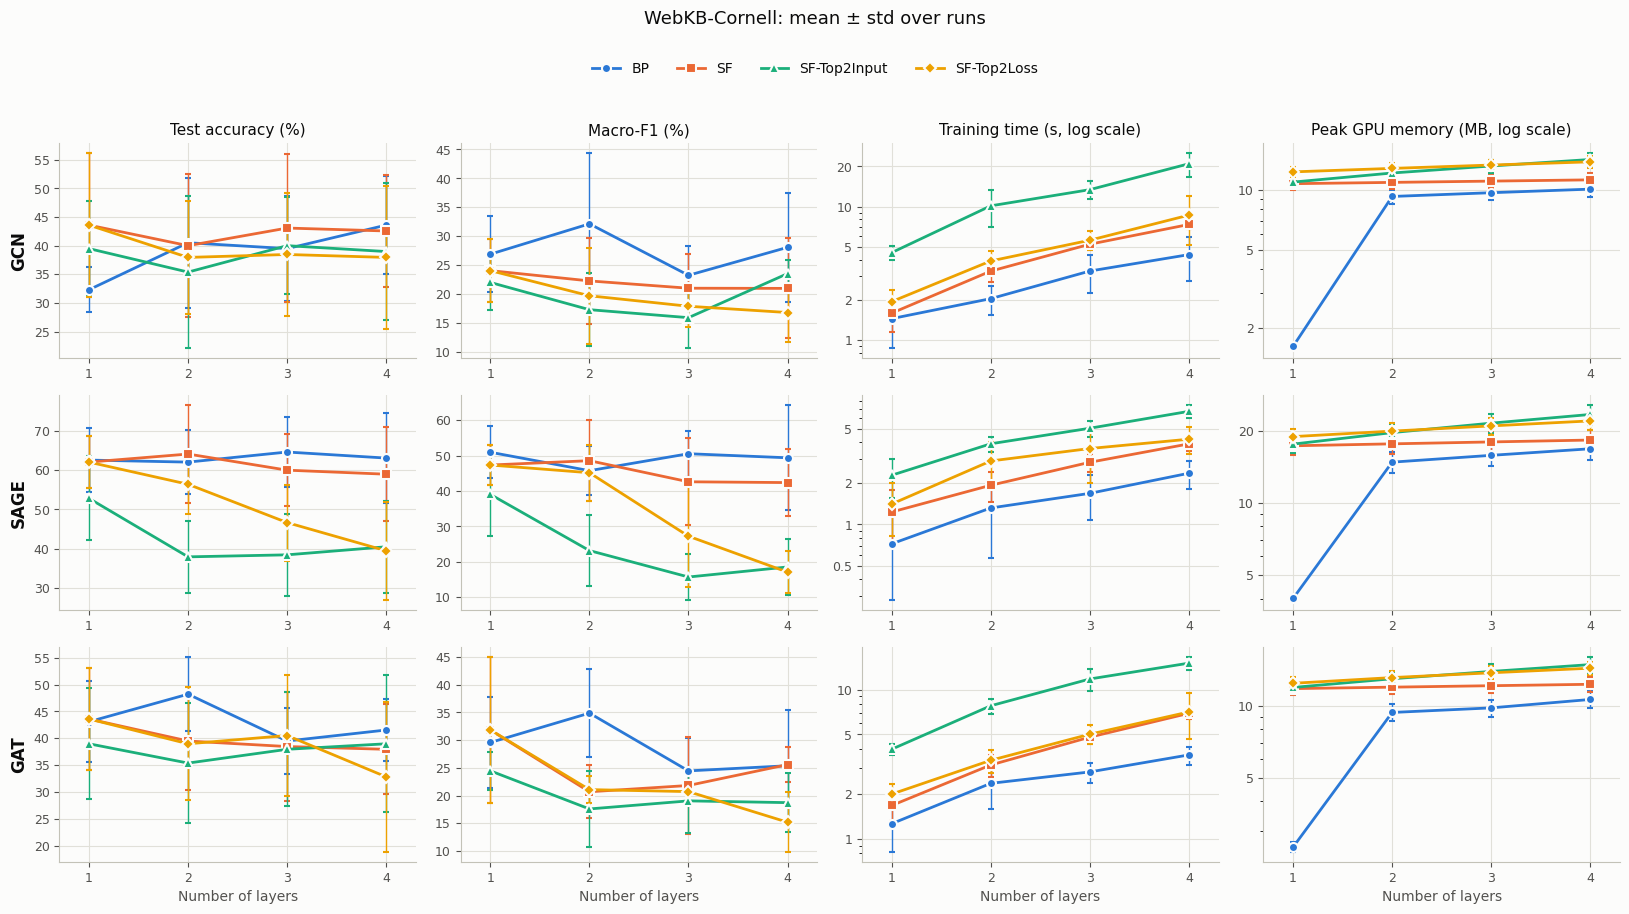

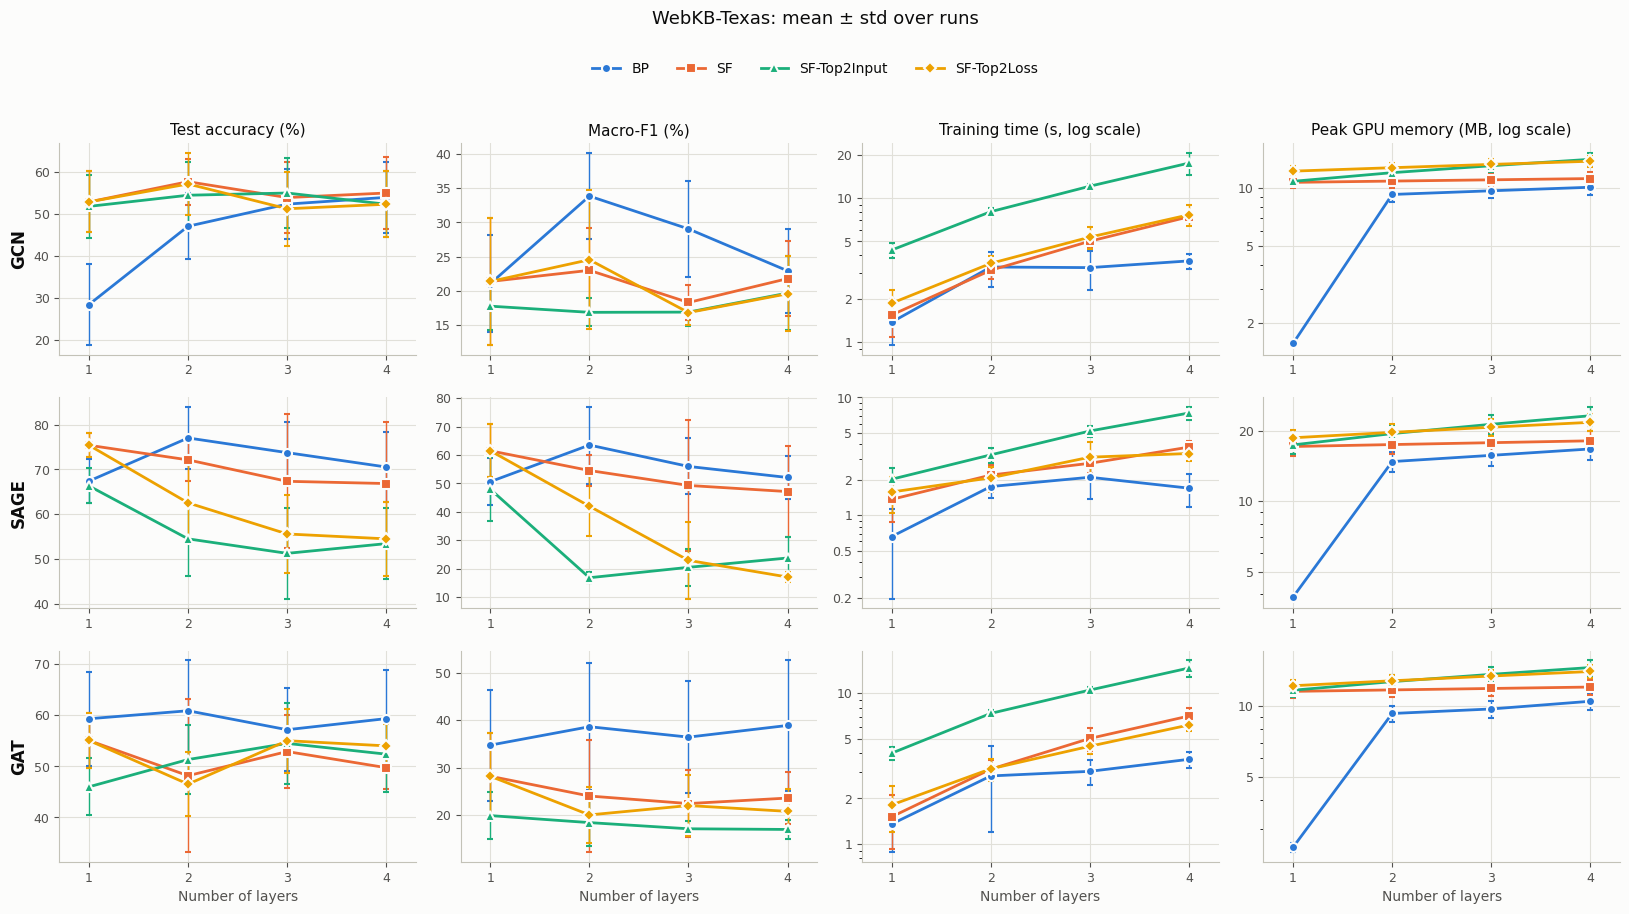

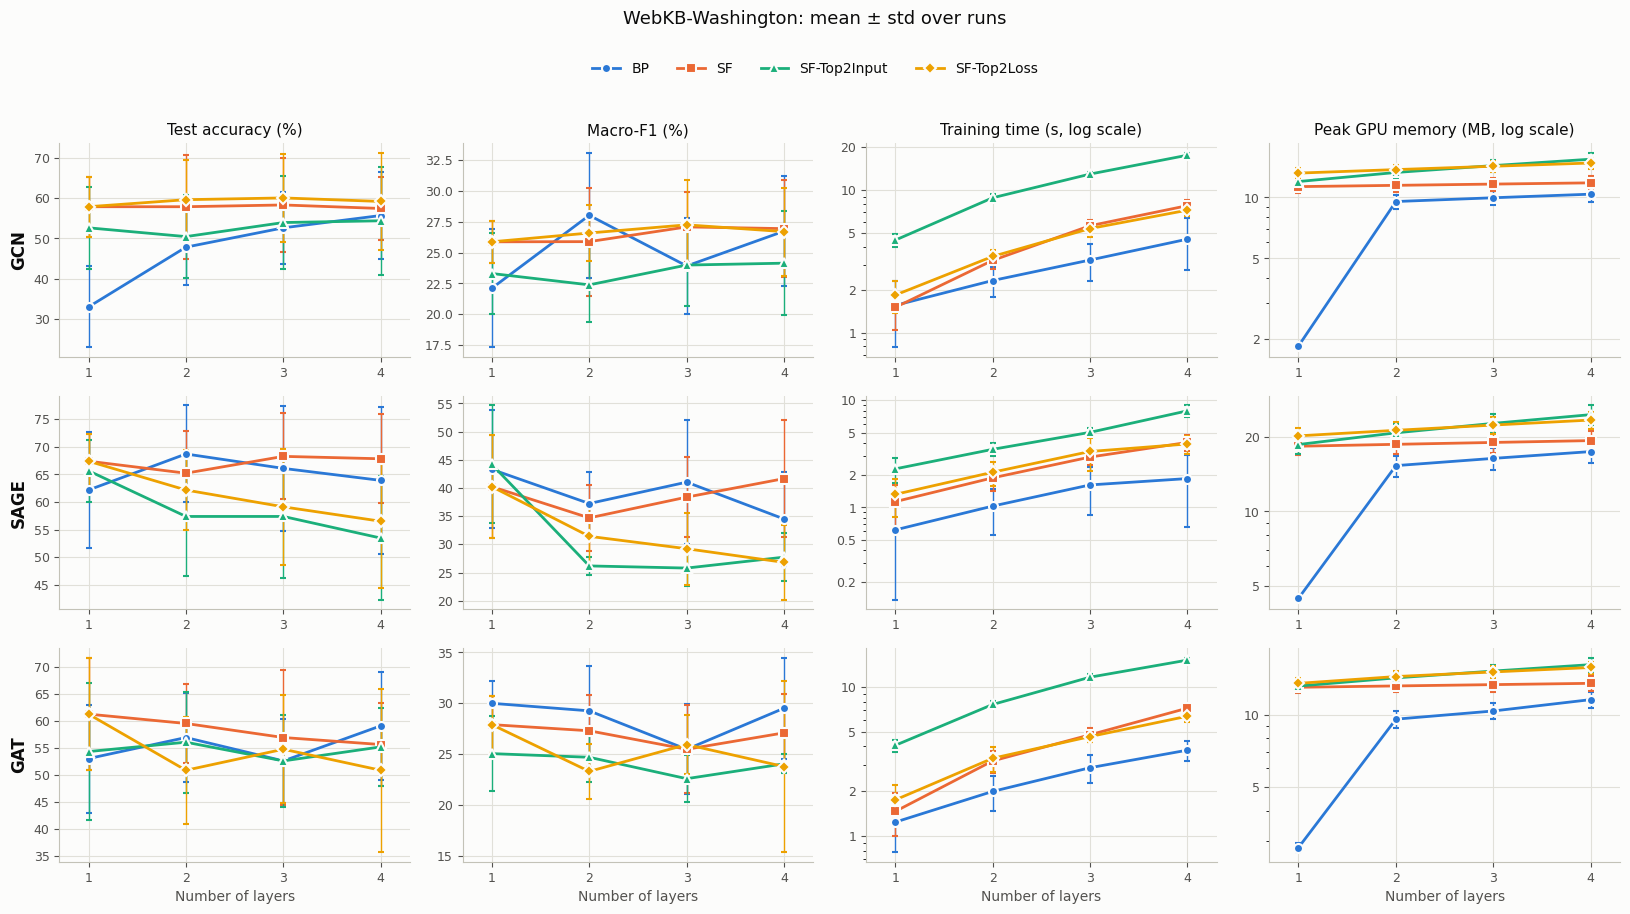

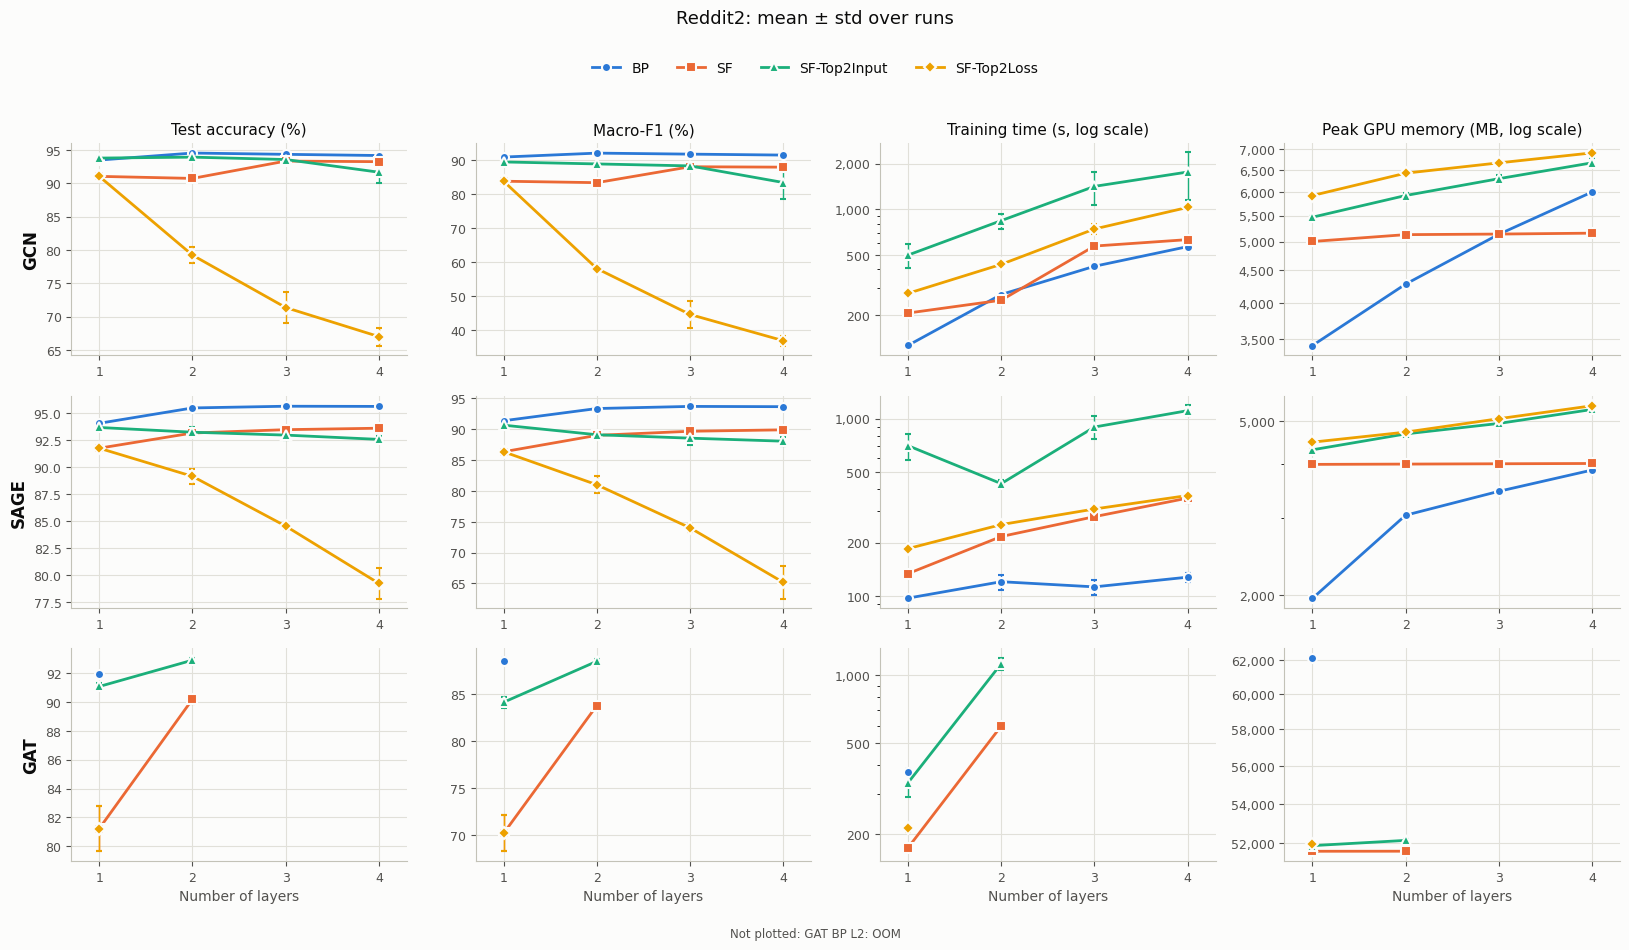

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

# Categorical slots 1-4 of a validated colour-blind-safe palette; marker shape is a second identity channel.
STYLE = {'BP': ('#2a78d6', 'o'), 'SF': ('#eb6834', 's'), 'SF-Top2Input': ('#1baf7a', '^'), 'SF-Top2Loss': ('#eda100', 'D')}
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
PANELS = [('acc', 'Test accuracy (%)', False), ('f1_macro', 'Macro-F1 (%)', False),
          ('train_time_s', 'Training time (s, log scale)', True),
          ('gpu_peak_alloc_train_mb', 'Peak GPU memory (MB, log scale)', True)]


def plot_dataset(dataset):
    data = summary[summary.dataset == dataset]
    fig, axes = plt.subplots(len(ARCHS), len(PANELS), figsize=(4.1 * len(PANELS), 2.9 * len(ARCHS)),
                             squeeze=False, facecolor=SURFACE)
    for r, arch in enumerate(ARCHS):
        for c, (metric, label, log) in enumerate(PANELS):
            ax = axes[r][c]
            ax.set_facecolor(SURFACE)
            for method in METHODS:
                sub = data[(data.arch == arch) & (data.method == method)].sort_values('depth')
                sub = sub[sub[f'{metric}_mean'].notna()]
                if sub.empty:
                    continue
                color, marker = STYLE[method]
                ax.errorbar(sub.depth, sub[f'{metric}_mean'], yerr=sub[f'{metric}_std'].fillna(0), color=color,
                            marker=marker, lw=2, ms=6.5, mec=SURFACE, mew=1.5, elinewidth=1, capsize=2,
                            solid_capstyle='round', solid_joinstyle='round')
            if not ax.has_data():
                no_gpu = metric.startswith('gpu') and summary[f'{metric}_mean'].isna().all()
                ax.text(0.5, 0.5, 'no GPU measurements' if no_gpu else 'no data yet', transform=ax.transAxes,
                        ha='center', va='center', color=MUTED, fontsize=10)
                ax.set_yticks([])
            elif log:
                ax.set_yscale('log')
                ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
                ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,g}'))
                ax.yaxis.set_minor_formatter(NullFormatter())
            ax.set_xticks(DEPTHS)
            ax.set_xlim(DEPTHS[0] - 0.3, DEPTHS[-1] + 0.3)
            ax.grid(True, color=GRID, lw=0.8)
            ax.set_axisbelow(True)
            for side in ('top', 'right'):
                ax.spines[side].set_visible(False)
            for side in ('left', 'bottom'):
                ax.spines[side].set_color(AXIS)
            ax.tick_params(colors=INK_2, labelsize=9)
            if r == 0:
                ax.set_title(label, color=INK, fontsize=11)
            if c == 0:
                ax.set_ylabel(arch, color=INK, fontsize=12, fontweight='semibold')
            if r == len(ARCHS) - 1:
                ax.set_xlabel('Number of layers', color=INK_2, fontsize=10)
    handles = [Line2D([], [], color=STYLE[m][0], marker=STYLE[m][1], lw=2, ms=6.5, mec=SURFACE, mew=1.5, label=m)
               for m in METHODS]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(METHODS),
               frameon=False, fontsize=10, labelcolor=INK)
    fig.suptitle(f'{dataset}: mean ± std over runs', y=1.045, color=INK, fontsize=13)
    missing = [f'{a} {m} L{L}: {s.upper()}' for (d, a, m, L), s in failed.items() if d == dataset]
    if missing:
        fig.text(0.5, -0.01, 'Not plotted: ' + '; '.join(missing), ha='center', va='top', color=INK_2,
                 fontsize=8.5, wrap=True)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(REPORT_DIR / f'figure_{dataset}.png', dpi=150, bbox_inches='tight', facecolor=SURFACE)
    plt.show()


for dataset in DATASETS:
    if dataset in set(summary.dataset):
        plot_dataset(dataset)

## 16. Each forward-learning method relative to backprop

Paired by run: the same data split and seed for both methods. Δ accuracy and Δ macro-F1 are percentage points (method − BP, mean ± std over the paired runs); the memory and time columns are ratios (method / BP, mean over the paired runs). Memory ratios below 1 mean the method needs less GPU memory than backprop at that depth.

In [ ]:
pair_keys = ['dataset', 'arch', 'depth', 'run_i']
bp = ok[ok.method == 'BP'].set_index(pair_keys)
parts = []


def mean_std(group):
    mean, std = group.mean().round(1), group.std().round(1)
    return mean.map('{:+.1f}'.format) + std.map(lambda s: '' if pd.isna(s) else f' ± {s:.1f}')


for method in [m for m in METHODS if m != 'BP']:
    cur = ok[ok.method == method].set_index(pair_keys)
    j = cur[list(METRICS)].join(bp[list(METRICS)], rsuffix='_bp', how='inner')
    if j.empty:
        continue
    j['d_acc'] = j['acc'] - j['acc_bp']
    j['d_f1'] = j['f1_macro'] - j['f1_macro_bp']
    j['mem_ratio'] = j['gpu_peak_alloc_train_mb'] / j['gpu_peak_alloc_train_mb_bp']
    j['time_ratio'] = j['train_time_excl_test_s'] / j['train_time_excl_test_s_bp']
    g = j.groupby(level=['dataset', 'arch', 'depth'])
    parts.append(pd.DataFrame({
        'method': method,
        'Δ acc (pp)': mean_std(g.d_acc),
        'Δ macro-F1 (pp)': mean_std(g.d_f1),
        'memory ×BP': g.mem_ratio.mean().round(2),
        'time ×BP (excl. test)': g.time_ratio.mean().round(2),
        'paired runs': g.size(),
    }))
if parts:
    relative = pd.concat(parts).reset_index().set_index(['dataset', 'arch', 'method', 'depth']).sort_index()
    display(relative)
    relative.to_csv(REPORT_DIR / 'relative_to_bp.csv')
else:
    print('No paired runs yet (BP and at least one forward method must have finished on the same splits).')

Δ acc (pp) Δ macro-F1 (pp)  \
dataset          arch method       depth                                
Reddit2          GAT  SF           1      -10.7 ± 1.6     -18.3 ± 1.9   
                      SF-Top2Input 1       -0.9 ± 0.3      -4.4 ± 0.7   
                      SF-Top2Loss  1      -10.7 ± 1.6     -18.3 ± 1.9   
                 GCN  SF           1       -2.4 ± 0.2      -7.1 ± 0.8   
                                   2       -3.8 ± 0.1      -8.7 ± 0.6   
...                                               ...             ...   
WebKB-Washington SAGE SF-Top2Input 4      -10.4 ± 9.4      -6.8 ± 8.8   
                      SF-Top2Loss  1       +5.2 ± 7.1     -3.1 ± 14.6   
                                   2       -6.5 ± 6.1      -5.8 ± 7.5   
                                   3       -7.0 ± 9.1    -11.8 ± 14.6   
                                   4       -7.4 ± 7.8      -7.7 ± 5.1   

                                          memory ×BP  time ×BP (excl. test)  \
dataset          arch method       depth                                      
Reddit2          GAT  SF           1            0.83                   0.43   
                      SF-Top2Input 1            0.83                   0.83   
                      SF-Top2Loss  1            0.84                   0.50   
                 GCN  SF           1            1.46                   1.37   
                                   2            1.20                   0.79   
...                                              ...                    ...   
WebKB-Washington SAGE SF-Top2Input 4            1.41                   5.15   
                      SF-Top2Loss  1            4.50                   2.48   
                                   2            1.39                   2.18   
                                   3            1.36                   2.29   
                                   4            1.34                   2.50   

                                          paired runs  
dataset          arch method       depth               
Reddit2          GAT  SF           1                5  
                      SF-Top2Input 1                5  
                      SF-Top2Loss  1                5  
                 GCN  SF           1                5  
                                   2                5  
...                                               ...  
WebKB-Washington SAGE SF-Top2Input 4                5  
                      SF-Top2Loss  1                5  
                                   2                5  
                                   3                5  
                                   4                5  

[135 rows x 5 columns]

## Notes and troubleshooting

**Reading the results**
- WebKB graphs are tiny (37–46 test nodes per split), so expect large standard deviations, and compare methods on the same splits (section 16) rather than only on means. They are also strongly heterophilic (edge homophily 0.06–0.15; Reddit2: 0.78), a setting where message passing is known to help little.
- Texas has a single `staff` page. In splits 0 and 1 it is not among the training nodes, so no method can learn that class there; when it is a test node, it lowers macro-F1 for every method alike.
- `gpu_peak_alloc_train_mb` includes the graph itself. The forward-learning code keeps a second, virtual-node copy of features and edges on the GPU, so at depth 1 backprop can need less memory than single-forward. The paper's memory claim concerns growth with depth.
- The time columns include early-stopping validation for every method. Use `train_time_excl_test_s` for like-for-like comparisons, and `train_time_s` to compare with the paper.
- Records keep the device, GPU name, library versions and every hyper-parameter, so runs from different GPUs can be told apart. Re-running a finished configuration does nothing; to redo one, delete its folder under `bench_records/<EXP_SETTING>/`.
- forwardgnn still writes its own result files to `results/<EXP_SETTING>/`. They are not used here: a depth-4 single-forward job also writes depth-1-to-3 files whose times and memory do not correspond to independent runs.

**Troubleshooting**
- *Reddit2 download fails or the checksum does not match.* Google Drive sometimes throttles. Re-run section 7; partial downloads are discarded, never used.
- *`OOM` cells.* Expected for some Reddit2 GAT configurations on 40 GB GPUs. With an 80 GB GPU, set `RETRY_FAILED = True` and re-run the cell.
- *`killed` cells.* The process died without an error (usually host RAM). Use a high-RAM runtime and retry.
- *`ModuleNotFoundError: torch_geometric.nn.conv.utils.inspector`* means PyG ≥ 2.3 got installed. Delete `/content/fgnn-env` and re-run section 4.
- *The backend check (section 8) reports a mismatch.* Set `MP_BACKEND = 'edge_index'`; most Reddit2 configurations will then run out of memory.
- *Comparing with your PubMed / GitHub / Amazon runs.* Those used forwardgnn's `NormalizeFeatures()` and the `edge_index` path. Set `FEATURE_NORM = 'row_l1'` and `MP_BACKEND = 'edge_index'` to run WebKB the same way; the results go to a separate `EXP_SETTING`.